# 09 — Pair-level analysis: which pairs are forgotten, by whom, and why

Notebook 08 counts **how much** each method forgets. This notebook looks at **which pairs**. Every run saves the
margin of every validation pair after every stage, so for every method, order, and seed we know exactly which
pairs were correct right after a behavior was learned and which were wrong at the end.

**Questions it answers**

1. Do different methods forget the **same pairs** or different ones? (compared with chance)
2. Do the two seeds forget the same pairs? Do different orders? (is forgetting a property of the pair?)
3. Is there a **core** of pairs that every method forgets?
4. Which pairs does each method **save** compared with No replay, and which does it newly forget?
5. What do fragile pairs look like? (learned margin, lengths, behavior, stage)
6. How do margins move stage by stage for forgotten vs kept pairs?
7. Are pairs whose **similar training pairs were replayed** forgotten less? (mechanism)
8. **The pairs themselves**: prompt, chosen and rejected responses, and every method's margins.

**How to use it**: same as notebook 08. Comment out methods in the settings cell, **Run All**, look, and keep what
you like with `save('F1')`, `save('T2')`, `save('all')`. Files go to `group26/artifacts/analysis/pair_level/`.
`show_pair('safe-val-0012')` shows any single pair in every run; `examples('core')` shows a group of pairs.

**Terms.** For each earlier behavior of a run (all behaviors except the last one trained):

| | correct at the end | wrong at the end |
|---|---|---|
| **correct right after learning** ("known") | kept | **forgotten** |
| **wrong right after learning** ("unknown") | **recovered** | never learned |

"Correct" means margin > 0. Pairs whose margin is very close to 0 at either point can flip by noise; they are
marked **borderline** and the main overlap results are repeated without them.

Validation split only (200 pairs per behavior), 8 development cells (orders 1–4 × seeds 0–1).

## 0. Settings

Edit only this cell, then Run All.

In [1]:
import json, os, re, math, shutil, warnings, html
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from IPython.display import HTML, display

ARTIFACTS = Path(os.environ.get('MFR_OUTPUT_DIR', '/project2/xiangren_1987/group26/artifacts'))

# ---- Methods to analyse: comment out a line to drop that method everywhere ----
METHODS = [
    'none',              # No replay (required)
    'random',            # Random 10% (required, the equal-budget baseline)
    'random_high',       # Random 14.3%
    'mfr',               # MFR (ours)
   # 'mfr_balanced',      # Balanced MFR
   # 'mfr_at_risk',       # At-Risk MFR
   # 'mfr_stochastic',    # Stochastic MFR (skipped automatically until all 8 cells exist)
    'lowest_margin',     # Lowest margin
   # 'dapr_weak',         # DAPR-weak
]
UPSET_METHODS = ['random', 'mfr', 'lowest_margin', 'random_high']   # at most 4 replay methods in the "who saves what" figure

ORDERS = [1, 2, 3, 4]
SEEDS = [0, 1]
SPLIT = 'val'                  # never 'test' before the method is frozen
MARGIN_COL = 'margin'          # 'margin_sum' for the secondary score
BASELINE = 'random'
ALLOW_PARTIAL = False
BORDERLINE_QUANTILE = 0.10     # a flip is "borderline" if either margin is inside the 10% of |margins| closest to 0
N_CHANCE = 2000                # random draws for every chance baseline
CHANCE_SEED = 544
NEIGHBORS = 5                  # nearest training pairs per validation pair (replay-link analysis)
N_EXAMPLES = 4                 # pairs shown per example group (change, or call examples('core', n=20))
TEXT_CHARS = 500               # characters of each text shown before "show all"
EXAMPLE_CELL = (1, 0)          # (order, seed) for the margin scatter
OUT = ARTIFACTS / 'analysis' / 'pair_level'

REPO = next((p for p in [Path.cwd(), Path.cwd().parent] if (p / 'configs/experiment_protocol.json').exists()), None)
PROTOCOL = json.loads((REPO / 'configs/experiment_protocol.json').read_text()) if REPO else {}
PROTOCOL_ORDERS = {int(k): list(v) for k, v in PROTOCOL.get('orders', {}).items()}
DATA_DIR = Path(os.environ.get('MFR_DATA_DIR', (REPO / 'data' / 'v2') if REPO else '/project2/xiangren_1987/group26/data/v2'))
print('artifacts:', ARTIFACTS, '| exists:', ARTIFACTS.exists())
print('pair text:', DATA_DIR, '| exists:', DATA_DIR.exists())
print('methods  :', ', '.join(METHODS))
print('save(...) writes to:', OUT)

artifacts: /project2/xiangren_1987/group26/artifacts | exists: True
pair text: /project2/xiangren_1987/group26/data/v2 | exists: True
methods  : none, random, random_high, mfr, lowest_margin
save(...) writes to: /project2/xiangren_1987/group26/artifacts/analysis/pair_level


### Labels, colors, and plot style

Colors follow one rule: a method keeps the same color in every figure. Random 14.3% is a lighter
step of Random 10%'s blue because it is the same rule with more slots. Every bar and point also has a
text label, so no result depends on color alone.

In [2]:
MLABEL = {'none': 'No replay', 'random': 'Random 10%', 'random_high': 'Random 14.3%',
          'lowest_margin': 'Lowest margin', 'mfr': 'MFR (ours)', 'mfr_balanced': 'Balanced MFR',
          'mfr_at_risk': 'At-Risk MFR', 'mfr_stochastic': 'Stochastic MFR', 'dapr_weak': 'DAPR-weak',
          'joint': 'Joint training'}
MCOLOR = {'none': '#8a8984', 'random': '#2a78d6', 'random_high': '#86b6ef', 'lowest_margin': '#1baf7a',
          'mfr': '#eb6834', 'mfr_balanced': '#eda100', 'mfr_at_risk': '#e87ba4', 'mfr_stochastic': '#e34948',
          'dapr_weak': '#6250d6', 'joint': '#0b0b0b'}
DATASETS = ['helpful', 'safe', 'quality']
DLABEL = {'helpful': 'Helpful', 'safe': 'Safe', 'quality': 'Quality'}
DCOLOR = {'helpful': '#2a78d6', 'safe': '#eb6834', 'quality': '#1baf7a'}
INK, INK2, GRID = '#0b0b0b', '#52514e', '#e5e4e0'
FORGET_C, RECOVER_C, NEUTRAL = '#e34948', '#2a78d6', '#f0efec'
DIVERGING = LinearSegmentedColormap.from_list('div', [FORGET_C, NEUTRAL, RECOVER_C])
SEQUENTIAL = LinearSegmentedColormap.from_list('seq', ['#cde2fb', '#86b6ef', '#2a78d6', '#184f95', '#0d366b'])
KEY_METHODS = ['none', 'random', 'mfr', 'lowest_margin', 'dapr_weak']   # for line charts (fewer series)

def _report_font():
    """Use Calibri/Carlito (the report's font). Carlito is free; download it once if missing."""
    from matplotlib import font_manager as fm
    have = {f.name for f in fm.fontManager.ttflist}
    for name in ['Calibri', 'Carlito']:
        if name in have:
            return name
    cache = Path.home() / '.cache' / 'mfr_fonts'
    try:
        import urllib.request
        cache.mkdir(parents=True, exist_ok=True)
        for style in ['Regular', 'Bold', 'Italic', 'BoldItalic']:
            path = cache / f'Carlito-{style}.ttf'
            if not path.exists():
                urllib.request.urlretrieve(f'https://github.com/google/fonts/raw/main/ofl/carlito/{path.name}', path)
            fm.fontManager.addfont(str(path))
        return 'Carlito'
    except Exception as error:
        print(f'Carlito not available ({error}); using DejaVu Sans.')
        return 'DejaVu Sans'

FONT = _report_font()
plt.rcParams.update({
    'font.family': FONT, 'font.size': 9.5, 'axes.titlesize': 9.5, 'axes.titleweight': 'bold',
    'axes.titlelocation': 'left', 'axes.titlepad': 6, 'axes.labelsize': 9.5, 'xtick.labelsize': 8.5,
    'ytick.labelsize': 9, 'legend.fontsize': 8.5, 'legend.frameon': False, 'legend.handlelength': 1.4,
    'legend.columnspacing': 1.2, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#8a8984', 'axes.linewidth': 0.8, 'axes.labelcolor': INK, 'xtick.color': INK2,
    'ytick.color': INK, 'xtick.major.size': 3, 'ytick.major.size': 0, 'text.color': INK,
    'grid.color': GRID, 'grid.linewidth': 0.7, 'lines.linewidth': 2, 'lines.markersize': 5,
    'figure.facecolor': 'white', 'axes.facecolor': 'white', 'figure.dpi': 150, 'savefig.dpi': 300,
    'figure.constrained_layout.use': True, 'pdf.fonttype': 42, 'ps.fonttype': 42,
})
FULL_W, HALF_W = 6.5, 3.25   # inches: full text width of the report, and half of it
print('Figure font:', FONT)

def num(value, digits=2, sign=False):
    """Number with a real minus sign (looks right in print)."""
    text = f'{value:+.{digits}f}' if sign else f'{value:.{digits}f}'
    return text.replace('-', '−')

display(HTML('''<style>.rt{border-collapse:collapse;font-size:12.5px;margin:6px 0 14px}
.rt th{background:#333;color:#fff;padding:5px 9px;text-align:left}
.rt td{padding:4px 9px;border-bottom:1px solid #ddd}</style>'''))

FIGURES, TABLES, TEXTS, CAPTIONS = {}, {}, {}, {}   # everything shown so far; save(...) writes from here

def show(df, name=None, caption=None, decimals=2):
    """Display a table (not saved; use save('T1') to keep it)."""
    out = df.copy()
    nums = out.select_dtypes(include='number').columns
    out[nums] = out[nums].round(decimals)
    label = f'[{name.split("_")[0]}] ' if name else ''
    if caption:
        display(HTML(f'<b>{label}{caption}</b>'))
    display(HTML(out.to_html(index=False, border=0, na_rep='—', classes='rt')))
    if name:
        TABLES[name] = out

def show_fig(fig, name, caption=''):
    """Display a figure with a suggested caption (not saved; use save('F1') to keep it)."""
    FIGURES[name] = fig
    CAPTIONS[name] = caption
    tag = name.split('_')[0]
    display(fig)
    plt.close(fig)
    display(HTML(f'<div style="max-width:900px;font-size:12.5px;color:#888;margin:2px 0 18px">'
                 f'<b>{tag}</b> &nbsp;suggested caption: {caption} &nbsp;&nbsp;'
                 f'<code>save(\'{tag}\')</code> keeps it.</div>'))

def _match(key, names):
    tag = key.split('_')[0]          # e.g. 'F1', 'T2a', 'key'
    return any(n == 'all' or key == n or tag == n or key.startswith(n + '_')
               or (tag.startswith(n) and tag[len(n):].isalpha()) for n in names)   # 'T2' -> T2a and T2b

def save(*names):
    """save('F1'), save('T1'), save('F1', 'T5'), save('key_numbers'), save('figures'), save('tables'), save('all')."""
    names = [str(n) for n in names] or ['all']
    figs = FIGURES if ('figures' in names) else {k: v for k, v in FIGURES.items() if _match(k, names)}
    tabs = TABLES if ('tables' in names) else {k: v for k, v in TABLES.items() if _match(k, names)}
    txts = {k: v for k, v in TEXTS.items() if _match(k, names)}
    if not (figs or tabs or txts):
        print('Nothing matched', names, '- run list_outputs() to see the names.')
        return
    for k, fig in figs.items():
        (OUT / 'figures').mkdir(parents=True, exist_ok=True)
        fig.savefig(OUT / 'figures' / f'{k}.png', bbox_inches='tight', pad_inches=0.04)
        fig.savefig(OUT / 'figures' / f'{k}.pdf', bbox_inches='tight', pad_inches=0.04)
        if CAPTIONS.get(k):
            (OUT / 'figures' / f'{k}_caption.txt').write_text(CAPTIONS[k] + '\n')
        print('saved', OUT / 'figures' / f'{k}.png', '(+ .pdf, caption)')
    for k, df in tabs.items():
        (OUT / 'tables').mkdir(parents=True, exist_ok=True)
        df.to_csv(OUT / 'tables' / f'{k}.csv', index=False)
        print('saved', OUT / 'tables' / f'{k}.csv')
    for k, text in txts.items():
        OUT.mkdir(parents=True, exist_ok=True)
        (OUT / f'{k}.txt').write_text(text + '\n')
        print('saved', OUT / f'{k}.txt')

def list_outputs():
    for kind, items in [('Figures', FIGURES), ('Tables', TABLES), ('Text', TEXTS)]:
        print(f'{kind}:')
        tags = [k.split('_')[0] for k in items]
        for k, tag in zip(items, tags):
            short = tag if (kind != 'Text' and tags.count(tag) == 1) else k
            print(f"   save('{short}')".ljust(26) + f'->  {k}')

def zip_saved():
    if not OUT.exists():
        print('Nothing saved yet.')
        return
    archive = shutil.make_archive(str(OUT.parent / 'pair_level_outputs'), 'zip', OUT)
    print('Zip:', archive)
    print(f'Download from your laptop:  scp <user>@discovery.usc.edu:{archive} ~/Downloads/')

def clean_axis(ax, grid='x'):
    if grid:
        ax.grid(axis=grid, color=GRID, lw=0.7)
        ax.set_axisbelow(True)

def no_frame(ax):
    for side in ax.spines.values():
        side.set_visible(False)
    ax.tick_params(length=0)

def method_axis(ax, methods):
    """Method names on the y axis, worst at the top, no left spine."""
    ax.set_yticks(range(len(methods)), [MLABEL[m] for m in methods])
    ax.set_ylim(len(methods) - 0.5, -0.7)
    ax.spines['left'].set_visible(False)
    ax.tick_params(axis='y', length=0)

Figure font: Carlito


## 1. Load the runs

A run is used only when its folder has `COMPLETE.json`, `settings.json`, and `results.csv`.
Methods other than No replay reuse the No replay run's Stage-1 model (`stage1_from`), so Stage 1 is
read from that run.

In [3]:
def read_json(path):
    return json.loads(Path(path).read_text())

def scan_runs(root):
    found = []
    runs_dir = Path(root) / 'runs'
    if not runs_dir.exists():
        return found
    for folder in sorted(runs_dir.glob('*')):
        needed = [folder / 'COMPLETE.json', folder / 'settings.json', folder / 'results.csv']
        if not all(p.exists() for p in needed):
            continue
        s = read_json(folder / 'settings.json')
        method = str(s.get('method'))
        if method not in METHODS:
            continue
        order_id, seed = int(s['order_id']), int(s['seed'])
        if order_id not in ORDERS or seed not in SEEDS:
            continue
        found.append({'run_name': s.get('run_name', folder.name), 'method': method, 'order_id': order_id,
                      'seed': seed, 'order': list(s['order']), 'folder': folder,
                      'stage1_from': s.get('stage1_from'),
                      'protocol_version': str(s.get('protocol_version')), 'data_version': str(s.get('data_version')),
                      'model_revision': str(s.get('model_revision'))})
    return found

for need in ['none', BASELINE]:
    assert need in METHODS, f"'{need}' is required; do not comment it out"
records = {(r['method'], r['order_id'], r['seed']): r for r in scan_runs(ARTIFACTS)}
if not records:
    raise FileNotFoundError(f'No completed runs found under {ARTIFACTS}/runs')

inventory = (pd.DataFrame(list(records.values()))
             .groupby('method').agg(cells=('run_name', 'count'),
                                    protocol=('protocol_version', lambda s: ', '.join(sorted(set(s)))),
                                    data=('data_version', lambda s: ', '.join(sorted(set(s)))))
             .reindex(METHODS).dropna(how='all').reset_index())
inventory['complete'] = inventory['cells'] == len(ORDERS) * len(SEEDS)
show(inventory.assign(method=inventory['method'].map(MLABEL)), 'T00_inventory', 'Runs found per method')

USED = [m for m in METHODS if m in set(inventory.loc[inventory['complete'] | ALLOW_PARTIAL, 'method'])]
missing = [m for m in METHODS if m not in USED]
print('Methods used:', ', '.join(MLABEL[m] for m in USED))
if missing:
    print('Not used (fewer than 8 cells or not found):', ', '.join(MLABEL[m] for m in missing))
for need in ['none', BASELINE]:
    assert need in USED, f'{MLABEL[need]} must have all 8 cells'
records = {k: v for k, v in records.items() if k[0] in USED}
for rec in records.values():
    if PROTOCOL_ORDERS:
        assert rec['order'] == PROTOCOL_ORDERS[rec['order_id']], f"order mismatch in {rec['run_name']}"

method,cells,protocol,data,complete
No replay,8,2.1,v2,True
Random 10%,8,2.1,v2,True
Random 14.3%,8,2.1,v2,True
MFR (ours),8,2.1,v2,True
Lowest margin,8,2.1,v2,True


Methods used: No replay, Random 10%, Random 14.3%, MFR (ours), Lowest margin


### 1.1 Are the comparisons fair?

Three checks before any number is trusted:

1. Every run uses the same data version and model revision.
2. Every method in a cell starts from the **identical Stage-1 model**: its Stage-1 validation margins
   must match the No replay run of that cell. This matters most for runs trained in the extended folder
   and copied here (for example DAPR-weak).
3. The accuracy recomputed from the pair-level margins equals `results.csv` (checked in section 3).

In [4]:
def stage_dir(rec, stage):
    d = rec['order'][stage - 1]
    direct = rec['folder'] / f'stage{stage}_{d}'
    if direct.exists() or stage != 1 or not rec['stage1_from']:
        return direct
    source = Path(rec['stage1_from'])
    if not source.exists():
        source = rec['folder'].parent / source.name
    return source / f'stage1_{d}'

def margins(rec, stage, dataset):
    path = stage_dir(rec, stage) / f'margins_{dataset}_{SPLIT}.csv'
    return pd.read_csv(path)

meta = pd.DataFrame(list(records.values()))
for column in ['data_version', 'model_revision', 'protocol_version']:
    values = sorted(meta[column].unique())
    flag = 'OK' if len(values) == 1 else 'CHECK: mixed values'
    print(f'{column:17s}: {values}  -> {flag}')

stage1_rows = []
for (method, order_id, seed), rec in records.items():
    if method == 'none':
        continue
    base = records[('none', order_id, seed)]
    first = rec['order'][0]
    a = margins(rec, 1, first)[['id', MARGIN_COL]].rename(columns={MARGIN_COL: 'margin'})
    b = margins(base, 1, first)[['id', MARGIN_COL]].rename(columns={MARGIN_COL: 'margin'})
    q = a.merge(b, on='id', suffixes=('', '_none'))
    stage1_rows.append({'method': method, 'order_id': order_id, 'seed': seed,
                        'pairs_matched': len(q), 'max_abs_margin_diff': float((q['margin'] - q['margin_none']).abs().max())})
stage1_check = pd.DataFrame(stage1_rows)
bad = stage1_check[(stage1_check['max_abs_margin_diff'] > 1e-4) | (stage1_check['pairs_matched'] < 200)]
summary_check = (stage1_check.groupby('method').agg(cells=('seed', 'count'), worst_diff=('max_abs_margin_diff', 'max'))
                 .reindex(USED).dropna().reset_index())
show(summary_check.assign(method=summary_check['method'].map(MLABEL)), 'T00_stage1_check',
     'Stage-1 identity check (worst difference from the No replay Stage-1 margins)', decimals=6)
if len(bad):
    warnings.warn(f'{len(bad)} runs do NOT share the No replay Stage-1 model. Inspect `bad` before reporting.')
    display(bad)
else:
    print('All methods share the identical Stage-1 model in every cell.')

data_version     : ['v2']  -> OK
model_revision   : ['989aa7980e4cf806f80c7fef2b1adb7bc71aa306']  -> OK
protocol_version : ['2.1']  -> OK


method,cells,worst_diff
Random 10%,8.0,0.0
Random 14.3%,8.0,0.0
MFR (ours),8.0,0.0
Lowest margin,8.0,0.0


All methods share the identical Stage-1 model in every cell.


## 2. The pairs: text and simple features

Prompt, chosen (preferred) and rejected responses from `data/v2/*_val.jsonl`, matched to the margins by `id`.

In [5]:
def read_jsonl(path):
    with open(path) as f:
        return [json.loads(line) for line in f if line.strip()]

def n_tokens(row, field):
    value = row.get(f'{field}_tokens')
    return float(value) if value is not None else float(len(str(row.get(field, '')).split()))

TEXT, info_rows = {}, []
for d in DATASETS:
    for r in read_jsonl(DATA_DIR / f'{d}_{SPLIT}.jsonl'):
        TEXT[r['id']] = r
        info_rows.append({'id': r['id'], 'dataset': d, 'source': r.get('source_dataset', ''),
                          'prompt_tokens': n_tokens(r, 'prompt'), 'chosen_tokens': n_tokens(r, 'chosen'),
                          'rejected_tokens': n_tokens(r, 'rejected')})
pair_info = pd.DataFrame(info_rows)
pair_info['length_gap'] = pair_info['chosen_tokens'] - pair_info['rejected_tokens']
print(f'{len(pair_info)} validation pairs with text:',
      ', '.join(f'{DLABEL[d]} {n}' for d, n in pair_info['dataset'].value_counts().reindex(DATASETS).items()))
show(pair_info.groupby('dataset')[['prompt_tokens', 'chosen_tokens', 'rejected_tokens', 'length_gap']].median()
     .reindex(DATASETS).reset_index().assign(dataset=lambda t: t['dataset'].map(DLABEL)),
     'T01_text_lengths', 'Median lengths (tokens) per behavior', decimals=0)

600 validation pairs with text: Helpful 200, Safe 200, Quality 200


dataset,prompt_tokens,chosen_tokens,rejected_tokens,length_gap
Helpful,58.0,262.0,228.0,17.0
Safe,53.0,77.0,92.0,-14.0
Quality,102.0,227.0,126.0,30.0


## 3. One row per pair, per run, per earlier behavior

`P` has, for every run and every earlier behavior, each validation pair's margin right after the behavior was
learned (`learned`), after every later stage (`m1`, `m2`, `m3`), at the end (`final`), and just before it was
learned (`before`, if saved). `status` is kept / forgotten / recovered / never. `borderline` marks flips where
either margin is very close to 0.

In [6]:
ORDER_SEQ = {}
for (method, order_id, seed), rec in records.items():
    ORDER_SEQ.setdefault(order_id, list(rec['order']))
ORDER_IDS = sorted(ORDER_SEQ)
ORDER_NAME = {o: ' → '.join(DLABEL[d] for d in ORDER_SEQ[o]) for o in ORDER_IDS}

def before_margins(rec, stage, dataset):
    """Margins of `dataset` just before it was trained (stage - 1)."""
    if stage >= 2:
        path = stage_dir(rec, stage - 1) / f'margins_{dataset}_{SPLIT}.csv'
    else:
        base = records.get(('none', rec['order_id'], rec['seed']))
        path = (base['folder'] / 'stage0_base' / f'margins_{dataset}_{SPLIT}.csv') if base else Path('/missing')
    return pd.read_csv(path).set_index('id')[MARGIN_COL] if path.exists() else None

frames = []
for (method, order_id, seed), rec in records.items():
    order, last = rec['order'], len(rec['order'])
    for k, d in enumerate(order[:-1], 1):
        df = pd.DataFrame({f'm{st}': margins(rec, st, d).set_index('id')[MARGIN_COL] for st in range(k, last + 1)})
        prior = before_margins(rec, k, d)
        df['before'] = prior.reindex(df.index) if prior is not None else np.nan
        df['learned'], df['final'] = df[f'm{k}'], df[f'm{last}']
        df = df.reset_index().rename(columns={'index': 'id'})
        df = df.assign(method=method, order_id=order_id, seed=seed, dataset=d, learned_at=k,
                       position='first' if k == 1 else 'second')
        frames.append(df)
P = pd.concat(frames, ignore_index=True)
for st in range(1, 4):
    if f'm{st}' not in P:
        P[f'm{st}'] = np.nan
known, right = P['learned'] > 0, P['final'] > 0
P['status'] = np.select([known & right, known & ~right, ~known & right], ['kept', 'forgotten', 'recovered'], 'never')
BAND = float(np.quantile(np.abs(P['learned'].to_numpy()), BORDERLINE_QUANTILE))
P['borderline'] = (P['learned'].abs() < BAND) | (P['final'].abs() < BAND)
P['drop'] = P['learned'] - P['final']
P = P.merge(pair_info.drop(columns='dataset'), on='id', how='left')
missing_text = P['prompt_tokens'].isna().sum()
SLOT = ['order_id', 'seed', 'dataset']

# Method order: worst to best net change (as in notebook 08)
net = (P.assign(k=known.astype(float), r=right.astype(float))
       .groupby(['method', 'order_id', 'seed', 'dataset'])[['k', 'r']].mean()
       .assign(net=lambda t: 100 * (t['r'] - t['k'])).groupby('method')['net'].mean())
order_methods = list(net.reindex(USED).sort_values().index)
REPLAY = [m for m in order_methods if m != 'none']
print(f'P: {len(P):,} rows = {P["method"].nunique()} methods × {P.groupby(["order_id", "seed"]).ngroups} cells × '
      f'2 earlier behaviors × 200 pairs')
print(f'Borderline band: |margin| < {BAND:.4g} ({BORDERLINE_QUANTILE:.0%} quantile of learned |margins|)')
if missing_text:
    print(f'WARNING: {missing_text} rows have no text match (check DATA_DIR)')

# check: accuracy from margins equals results.csv
res = []
for (method, order_id, seed), rec in records.items():
    frame = pd.read_csv(rec['folder'] / 'results.csv')
    last = len(rec['order'])
    for d in rec['order'][:-1]:
        row = frame[(frame['stage'] == last) & (frame['eval_set'] == d)]
        mine = 100 * (P[(P['method'] == method) & (P['order_id'] == order_id) & (P['seed'] == seed)
                        & (P['dataset'] == d)]['final'] > 0).mean()
        res.append(abs(mine - float(row.iloc[0]['accuracy'])) if len(row) and MARGIN_COL == 'margin' else 0.0)
print('Final accuracy from margins matches results.csv.' if max(res) < 0.051 else f'WARNING: mismatch up to {max(res):.2f} points')

P: 16,000 rows = 5 methods × 8 cells × 2 earlier behaviors × 200 pairs
Borderline band: |margin| < 0.001267 (10% quantile of learned |margins|)
Final accuracy from margins matches results.csv.


## 4. How many pairs move?

Per run, summed over its two earlier behaviors (400 pairs). Mean over the 8 cells.

In [7]:
cnt = (P.groupby(['method', 'order_id', 'seed', 'status']).size().unstack(fill_value=0)
       .reindex(columns=['kept', 'forgotten', 'recovered', 'never'], fill_value=0))
bl = P[P['status'].isin(['forgotten', 'recovered'])].groupby(['method', 'order_id', 'seed', 'status'])['borderline'].mean().unstack()
t1 = cnt.groupby('method').mean().reindex(order_methods)
t1['net (recovered − forgotten)'] = t1['recovered'] - t1['forgotten']
t1['forgotten: borderline %'] = 100 * bl['forgotten'].groupby('method').mean().reindex(order_methods)
t1['recovered: borderline %'] = 100 * bl['recovered'].groupby('method').mean().reindex(order_methods)
t1 = t1.reset_index().rename(columns={'method': 'Method'})
t1['Method'] = t1['Method'].map(MLABEL)
show(t1, 'T1_pair_counts', 'Table 1. Pairs per run in each box (mean over 8 cells; 400 earlier-behavior pairs per run)', decimals=1)

status,Method,kept,forgotten,recovered,never,net (recovered − forgotten),forgotten: borderline %,recovered: borderline %
,No replay,254.4,52.4,20.6,72.6,-31.8,27.0,44.3
,Random 10%,264.4,40.6,18.6,76.4,-22.0,37.9,55.1
,Random 14.3%,264.6,39.9,18.0,77.5,-21.9,40.2,54.8
,MFR (ours),267.6,36.2,16.8,79.4,-19.5,43.6,58.2
,Lowest margin,268.0,36.6,18.8,76.6,-17.9,39.2,51.5


## 5. Do methods forget the same pairs?

In each cell (order, seed) and earlier behavior, compare the sets of forgotten pairs of two methods with the
**Jaccard overlap** = |both| / |either|. Averaged over the 16 cell × behavior slots.

**Chance**: the overlap expected if each method forgot the same *number* of pairs, drawn at random from the pairs
it knew ({N} draws). Ratio > 1 means the methods forget the same pairs more than chance; p is the share of random
draws with an overlap at least as large. The same is done for recovered pairs (drawn from the pairs it did not know).

In [8]:
def draw_like(pool, k, n, rng):
    """n random subsets of size k from the True positions of `pool` (boolean array)."""
    out = np.zeros((n, len(pool)), bool)
    idx = np.flatnonzero(pool)
    k = min(int(k), len(idx))
    if k == 0:
        return out
    pick = np.argpartition(rng.random((n, len(idx))), k - 1, axis=1)[:, :k]
    out[np.repeat(np.arange(n), k), idx[pick.ravel()]] = True
    return out

def jaccard_vs_chance(data, slot_keys, unit_key, status, compare, skip_borderline=False, n=N_CHANCE, seed=CHANCE_SEED):
    rng = np.random.default_rng(seed)
    obs, sims = {}, {}
    for _, g in data.groupby(slot_keys):
        ids = pd.Index(sorted(g['id'].unique()))
        masks, samples = {}, {}
        for unit, gu in g.groupby(unit_key):
            j = ids.get_indexer(gu['id'])
            knew = (gu['learned'] > 0).to_numpy()
            hit_u = (gu['status'] == status).to_numpy()
            if skip_borderline:
                hit_u = hit_u & ~gu['borderline'].to_numpy()
            pool, hit = np.zeros(len(ids), bool), np.zeros(len(ids), bool)
            pool[j] = knew if status == 'forgotten' else ~knew
            hit[j] = hit_u
            masks[unit], samples[unit] = hit, draw_like(pool, hit.sum(), n, rng)
        for key, a, b in compare(list(masks)):
            union = (masks[a] | masks[b]).sum()
            if union == 0:
                continue
            obs.setdefault(key, []).append((masks[a] & masks[b]).sum() / union)
            su, si = (samples[a] | samples[b]).sum(1), (samples[a] & samples[b]).sum(1)
            sims.setdefault(key, []).append(np.where(su > 0, si / np.maximum(su, 1), np.nan))
    rows = []
    for key, values in obs.items():
        o = float(np.mean(values))
        with warnings.catch_warnings():
            warnings.simplefilter('ignore', RuntimeWarning)
            s = np.nanmean(np.vstack(sims[key]), axis=0)
        c = float(np.nanmean(s))
        rows.append({'key': key, 'observed': o, 'chance': c, 'ratio': o / c if c > 0 else np.nan,
                     'p': (1 + np.sum(s >= o)) / (1 + np.isfinite(s).sum()), 'slots': len(values)})
    return pd.DataFrame(rows)

RANK = {m: i for i, m in enumerate(order_methods)}
def all_pairs(units):
    units = sorted(units, key=RANK.get)
    return [((a, b), a, b) for i, a in enumerate(units) for b in units[i + 1:]]

def overlap_matrix(table):
    mat = pd.DataFrame(np.nan, index=order_methods, columns=order_methods)
    ratio = mat.copy()
    for _, r in table.iterrows():
        a, b = r['key']
        mat.loc[b, a] = mat.loc[a, b] = r['observed']
        ratio.loc[b, a] = ratio.loc[a, b] = r['ratio']
    return mat, ratio

def overlap_rows(table, label):
    t = table.copy()
    t['Method A'] = [MLABEL[k[0]] for k in t['key']]
    t['Method B'] = [MLABEL[k[1]] for k in t['key']]
    t['What'] = label
    return t[['What', 'Method A', 'Method B', 'observed', 'chance', 'ratio', 'p', 'slots']].rename(
        columns={'observed': 'Jaccard', 'chance': 'Chance Jaccard', 'ratio': 'Ratio to chance', 'p': 'p (chance)'})

ov_forgot = jaccard_vs_chance(P, SLOT, 'method', 'forgotten', all_pairs)
ov_recov = jaccard_vs_chance(P, SLOT, 'method', 'recovered', all_pairs)
ov_forgot_clear = jaccard_vs_chance(P, SLOT, 'method', 'forgotten', all_pairs, skip_borderline=True)
ov_forgot_first = jaccard_vs_chance(P[P['learned_at'] == 1], SLOT, 'method', 'forgotten', all_pairs)
show(overlap_rows(ov_forgot, 'forgotten'), 'T2a_overlap_forgotten',
     'Table 2a. Overlap of forgotten pairs between methods (same cell and behavior)', decimals=3)
show(overlap_rows(ov_recov, 'recovered'), 'T2b_overlap_recovered',
     'Table 2b. Overlap of recovered pairs between methods', decimals=3)
show(pd.concat([overlap_rows(ov_forgot_clear, 'forgotten, no borderline flips'),
                overlap_rows(ov_forgot_first, 'forgotten, first behavior only (identical start)')]),
     'T2c_overlap_robustness', 'Table 2c. Robustness: without borderline flips, and first-learned behavior only', decimals=3)

What,Method A,Method B,Jaccard,Chance Jaccard,Ratio to chance,p (chance),slots
forgotten,No replay,Random 10%,0.667,0.081,8.230,0.0,16
forgotten,No replay,Random 14.3%,0.633,0.080,7.915,0.0,16
forgotten,No replay,MFR (ours),0.592,0.075,7.908,0.0,16
forgotten,No replay,Lowest margin,0.553,0.075,7.362,0.0,16
forgotten,Random 10%,Random 14.3%,0.832,0.073,11.472,0.0,16
forgotten,Random 10%,MFR (ours),0.752,0.069,10.968,0.0,16
forgotten,Random 10%,Lowest margin,0.672,0.069,9.776,0.0,16
forgotten,Random 14.3%,MFR (ours),0.778,0.069,11.288,0.0,16
forgotten,Random 14.3%,Lowest margin,0.661,0.069,9.636,0.0,16
forgotten,MFR (ours),Lowest margin,0.670,0.065,10.287,0.0,16


What,Method A,Method B,Jaccard,Chance Jaccard,Ratio to chance,p (chance),slots
recovered,No replay,Random 10%,0.645,0.115,5.605,0.0,16
recovered,No replay,Random 14.3%,0.609,0.110,5.531,0.0,16
recovered,No replay,MFR (ours),0.551,0.106,5.206,0.0,16
recovered,No replay,Lowest margin,0.573,0.113,5.091,0.0,16
recovered,Random 10%,Random 14.3%,0.886,0.107,8.270,0.0,16
recovered,Random 10%,MFR (ours),0.738,0.102,7.220,0.0,16
recovered,Random 10%,Lowest margin,0.598,0.108,5.519,0.0,16
recovered,Random 14.3%,MFR (ours),0.702,0.100,7.057,0.0,16
recovered,Random 14.3%,Lowest margin,0.644,0.107,6.047,0.0,16
recovered,MFR (ours),Lowest margin,0.634,0.102,6.216,0.0,16


What,Method A,Method B,Jaccard,Chance Jaccard,Ratio to chance,p (chance),slots
"forgotten, no borderline flips",No replay,Random 10%,0.622,0.051,12.224,0.0,16
"forgotten, no borderline flips",No replay,Random 14.3%,0.562,0.049,11.480,0.0,16
"forgotten, no borderline flips",No replay,MFR (ours),0.506,0.044,11.436,0.0,16
"forgotten, no borderline flips",No replay,Lowest margin,0.486,0.047,10.416,0.0,16
"forgotten, no borderline flips",Random 10%,Random 14.3%,0.821,0.042,19.349,0.0,16
"forgotten, no borderline flips",Random 10%,MFR (ours),0.695,0.039,17.751,0.0,16
"forgotten, no borderline flips",Random 10%,Lowest margin,0.657,0.041,16.209,0.0,16
"forgotten, no borderline flips",Random 14.3%,MFR (ours),0.700,0.039,18.006,0.0,16
"forgotten, no borderline flips",Random 14.3%,Lowest margin,0.634,0.040,16.003,0.0,16
"forgotten, no borderline flips",MFR (ours),Lowest margin,0.638,0.037,17.407,0.0,16


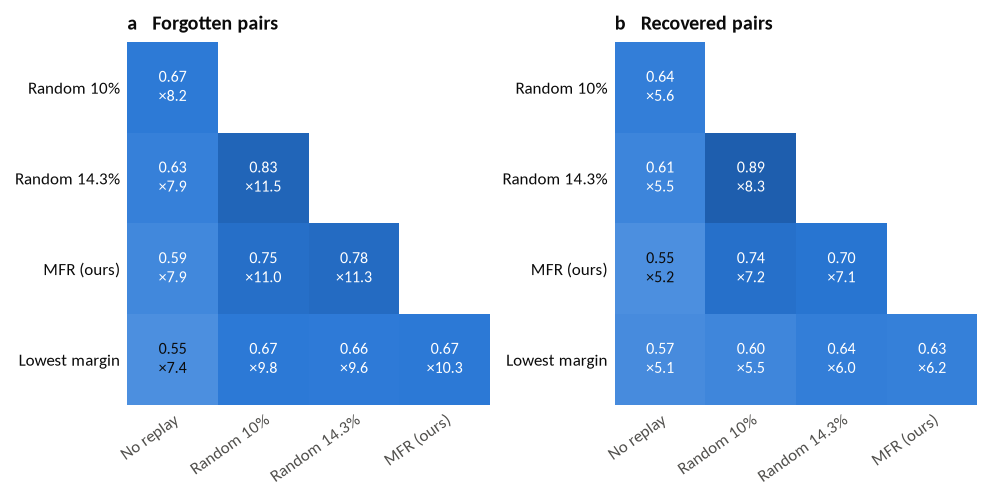

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(FULL_W, 0.42 * len(order_methods) + 1.5))
vmax = max(0.05, 1.15 * max(ov_forgot['observed'].max(), ov_recov['observed'].max() if len(ov_recov) else 0))
for ax, (table, title) in zip(axes, [(ov_forgot, 'a   Forgotten pairs'), (ov_recov, 'b   Recovered pairs')]):
    mat, ratio = overlap_matrix(table)
    n = len(order_methods)
    show_mat = np.full((n, n), np.nan)
    for i in range(n):
        for j in range(i):
            show_mat[i, j] = mat.iloc[i, j]
    ax.imshow(show_mat, cmap=LinearSegmentedColormap.from_list('ov', ['#f4f8fe', '#86b6ef', '#2a78d6', '#184f95']),
              vmin=0, vmax=vmax)
    for i in range(n):
        for j in range(i):
            v, r = mat.iloc[i, j], ratio.iloc[i, j]
            ax.text(j, i, f'{v:.2f}\n×{r:.1f}', ha='center', va='center', fontsize=7.5,
                    color='white' if v > 0.55 * vmax else INK)
    ax.set_xticks(range(n - 1), [MLABEL[m] for m in order_methods[:-1]], rotation=35, ha='right',
                  rotation_mode='anchor', fontsize=8)
    ax.set_yticks(range(1, n), [MLABEL[m] for m in order_methods[1:]], fontsize=8)
    ax.set_xlim(-0.5, n - 1.5)
    ax.set_ylim(n - 0.5, 0.5)
    ax.set_title(title)
    no_frame(ax)
show_fig(fig, 'F1_overlap_between_methods',
         'Overlap (Jaccard) of the pairs two methods forget (a) or recover (b) in the same cell and behavior, mean over '
         '16 cell × behavior slots. ×: ratio to the overlap expected by chance for sets of the same size.')

## 6. Is forgetting a property of the pair?

Three checks, from strict to loose:

1. **Same method, other seed**: does seed 1 forget the pairs seed 0 forgot (same order)?
2. **Other orders**: per pair, the share of runs that forget it in one order vs another order (rank correlation).
3. **How concentrated is forgetting?** Per pair, the share of all runs (methods × orders × seeds) in which it was
   forgotten, compared with what chance would give.

Method,"Same method, other seed",chance (seed),"Other methods, same seed (mean)",chance (method)
No replay,0.511,0.089,0.611,0.078
Random 10%,0.477,0.069,0.731,0.073
Random 14.3%,0.488,0.068,0.726,0.073
MFR (ours),0.447,0.062,0.698,0.069
Lowest margin,0.369,0.061,0.639,0.069


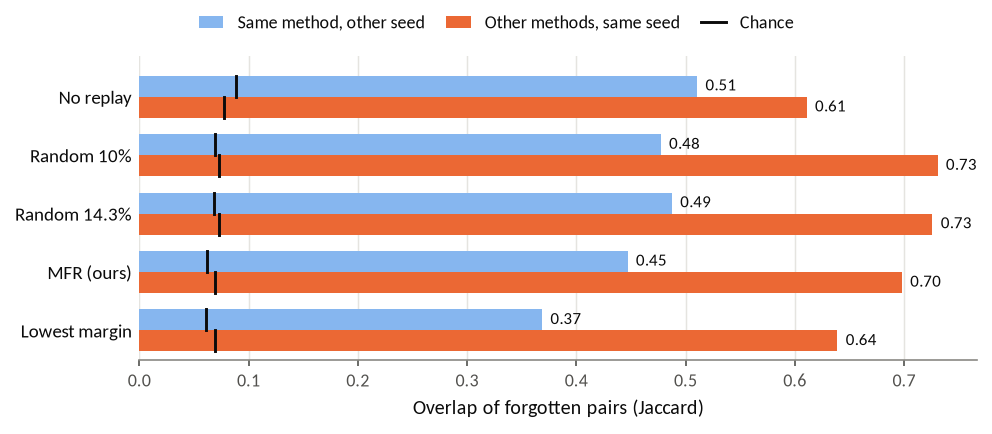

In [10]:
def same_method_other_seed(units):
    out = []
    for m in order_methods:
        if (m, SEEDS[0]) in units and (m, SEEDS[-1]) in units:
            out.append((('same', m), (m, SEEDS[0]), (m, SEEDS[-1])))
    for a, b in [(x, y) for i, x in enumerate(order_methods) for y in order_methods[i + 1:]]:
        if (a, SEEDS[0]) in units and (b, SEEDS[-1]) in units:
            out.append((('other', a + '|' + b), (a, SEEDS[0]), (b, SEEDS[-1])))
    return out

seed_ov = jaccard_vs_chance(P, ['order_id', 'dataset'], ['method', 'seed'], 'forgotten', same_method_other_seed)
same_seed = ov_forgot.copy()
rows = []
for m in order_methods:
    s = seed_ov[seed_ov['key'] == ('same', m)]
    cross = same_seed[[m in k for k in same_seed['key']]]
    rows.append({'Method': MLABEL[m],
                 'Same method, other seed': float(s['observed'].iloc[0]) if len(s) else np.nan,
                 'chance (seed)': float(s['chance'].iloc[0]) if len(s) else np.nan,
                 'Other methods, same seed (mean)': cross['observed'].mean(),
                 'chance (method)': cross['chance'].mean()})
other = seed_ov[[k[0] == 'other' for k in seed_ov['key']]]
t3 = pd.DataFrame(rows)
show(t3, 'T3_seed_vs_method_overlap',
     f'Table 3. Overlap of forgotten pairs: same method across seeds vs other methods in the same seed '
     f'(other method AND other seed: {other["observed"].mean():.3f}, chance {other["chance"].mean():.3f})', decimals=3)

fig, ax = plt.subplots(figsize=(FULL_W, 0.36 * len(order_methods) + 1.0))
h = 0.36
for y, r in t3.iterrows():
    ax.barh(y - h / 2, r['Same method, other seed'], height=h, color='#86b6ef', zorder=2,
            label='Same method, other seed' if y == 0 else None)
    ax.barh(y + h / 2, r['Other methods, same seed (mean)'], height=h, color='#eb6834', zorder=2,
            label='Other methods, same seed' if y == 0 else None)
    for dy, c in [(-h / 2, r['chance (seed)']), (h / 2, r['chance (method)'])]:
        ax.plot([c, c], [y + dy - h / 2, y + dy + h / 2], color=INK, lw=1.4, zorder=3,
                label='Chance' if (y == 0 and dy < 0) else None)
    ax.annotate(f"{r['Same method, other seed']:.2f}", (max(r['Same method, other seed'], r['chance (seed)']), y - h / 2),
                xytext=(4, 0), textcoords='offset points', va='center', fontsize=8)
    ax.annotate(f"{r['Other methods, same seed (mean)']:.2f}", (max(r['Other methods, same seed (mean)'], r['chance (method)']),
                y + h / 2), xytext=(4, 0), textcoords='offset points', va='center', fontsize=8)
method_axis(ax, order_methods)
ax.set_xlabel('Overlap of forgotten pairs (Jaccard)')
clean_axis(ax, 'x')
hs, ls = ax.get_legend_handles_labels()
fig.legend([hs[ls.index(x)] for x in ['Same method, other seed', 'Other methods, same seed', 'Chance']],
           ['Same method, other seed', 'Other methods, same seed', 'Chance'], loc='outside upper center', ncol=3)
show_fig(fig, 'F2_seed_vs_method_overlap',
         'How much the forgotten sets overlap when only the seed changes (light blue) or only the method changes '
         '(orange). Black ticks: chance for sets of the same size.')

Behavior,Order A,Order B,Pairs,Spearman ρ
Helpful,1: Helpful → Safe → Quality,2: Safe → Helpful → Quality,143,0.883
Helpful,1: Helpful → Safe → Quality,3: Quality → Helpful → Safe,141,0.551
Helpful,2: Safe → Helpful → Quality,3: Quality → Helpful → Safe,140,0.465
Safe,1: Helpful → Safe → Quality,2: Safe → Helpful → Quality,173,0.871
Safe,1: Helpful → Safe → Quality,4: Quality → Safe → Helpful,173,0.785
Safe,2: Safe → Helpful → Quality,4: Quality → Safe → Helpful,171,0.792
Quality,3: Quality → Helpful → Safe,4: Quality → Safe → Helpful,156,0.421


The 10% most-forgotten pairs account for 59.7% of all forgetting events (chance: 21.6%).
Pairs forgotten in at least half the runs where they were known: 89 (chance 2.1).  Never forgotten: 324 (chance 35.7).


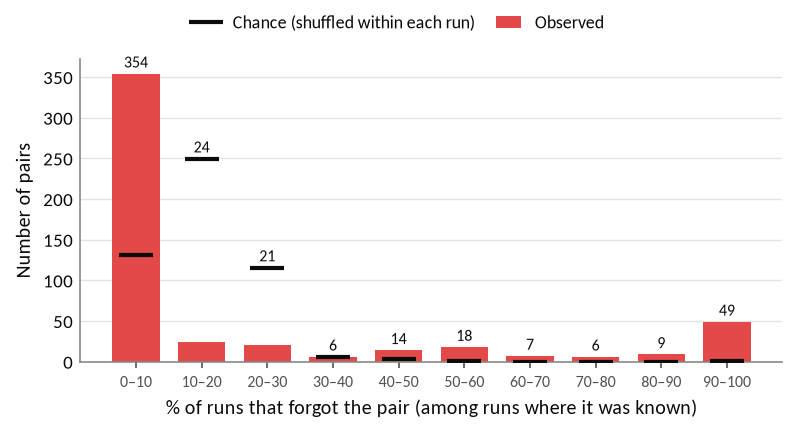

In [11]:
# 2. Across orders: per pair, forget rate within each order (pooled over methods and seeds)
pk = P[P['learned'] > 0]
rate_o = pk.groupby(['dataset', 'id', 'order_id'])['status'].apply(lambda s: (s == 'forgotten').mean()).unstack()
rows = []
for d in DATASETS:
    r = rate_o.loc[d] if d in rate_o.index.get_level_values(0) else None
    if r is None:
        continue
    cols = [o for o in ORDER_IDS if o in r.columns and r[o].notna().sum() > 20]
    for i, a in enumerate(cols):
        for b in cols[i + 1:]:
            both = r[[a, b]].dropna()
            rows.append({'Behavior': DLABEL[d], 'Order A': f'{a}: {ORDER_NAME[a]}', 'Order B': f'{b}: {ORDER_NAME[b]}',
                         'Pairs': len(both), 'Spearman ρ': both[a].corr(both[b], method='spearman')})
t4 = pd.DataFrame(rows)
show(t4, 'T4_fragility_across_orders',
     'Table 4. Do the same pairs get forgotten in different orders? Rank correlation of per-pair forget rates '
     '(0 = unrelated, 1 = same pairs)', decimals=3)

# 3. Concentration: per pair, share of runs that forget it, vs chance (forgotten labels shuffled within each run)
runs_key = ['method', 'order_id', 'seed', 'dataset']
pk = pk.assign(f=(pk['status'] == 'forgotten').astype(int))
per_pair = pk.groupby(['dataset', 'id']).agg(runs=('f', 'size'), forgotten=('f', 'sum'))
per_pair['rate'] = per_pair['forgotten'] / per_pair['runs']
bins = np.linspace(0, 1, 11)
obs_hist = np.histogram(per_pair['rate'], bins=bins)[0]
rng = np.random.default_rng(CHANCE_SEED)
pk = pk.reset_index(drop=True)
f_values = pk['f'].to_numpy().copy()
group_pos = list(pk.groupby(runs_key).indices.values())
inv = pd.factorize(pk['dataset'] + '|' + pk['id'])[0]
runs_per_pair = np.bincount(inv)
chance_hists, chance_top, chance_half, chance_zero = [], [], [], []
for _ in range(200):
    sh = f_values.copy()
    for gp in group_pos:
        sh[gp] = rng.permutation(sh[gp])
    rate = np.bincount(inv, weights=sh) / runs_per_pair
    chance_hists.append(np.histogram(rate, bins=bins)[0])
    chance_half.append((rate >= 0.5).sum())
    chance_zero.append((rate == 0).sum())
    s = np.sort(np.bincount(inv, weights=sh))[::-1]
    chance_top.append(s[: max(1, len(s) // 10)].sum() / max(s.sum(), 1))
chance_hist = np.mean(chance_hists, axis=0)
s = np.sort(per_pair['forgotten'].to_numpy())[::-1]
top_share = s[: max(1, len(s) // 10)].sum() / max(s.sum(), 1)
TOP10 = (100 * top_share, 100 * float(np.mean(chance_top)))
print(f'The 10% most-forgotten pairs account for {TOP10[0]:.1f}% of all forgetting events '
      f'(chance: {TOP10[1]:.1f}%).')
print(f'Pairs forgotten in at least half the runs where they were known: {(per_pair["rate"] >= 0.5).sum()} '
      f'(chance {np.mean(chance_half):.1f}).  Never forgotten: {(per_pair["rate"] == 0).sum()} (chance {np.mean(chance_zero):.1f}).')

fig, ax = plt.subplots(figsize=(FULL_W * 0.8, 2.8))
x = np.arange(len(obs_hist))
ax.bar(x, obs_hist, width=0.72, color=FORGET_C, zorder=2, label='Observed')
ax.plot(x, chance_hist, color=INK, lw=0, marker='_', ms=16, mew=2, zorder=3, label='Chance (shuffled within each run)')
for xi, v, c in zip(x, obs_hist, chance_hist):
    ax.annotate(str(v), (xi, max(v, c)), xytext=(0, 3), textcoords='offset points', ha='center', fontsize=7.5)
ax.set_xticks(x, [f'{int(100 * a)}–{int(100 * b)}' for a, b in zip(bins[:-1], bins[1:])], fontsize=7.5)
ax.set_xlabel('% of runs that forgot the pair (among runs where it was known)')
ax.set_ylabel('Number of pairs')
clean_axis(ax, 'y')
fig.legend(loc='outside upper center', ncol=2)
show_fig(fig, 'F3_how_concentrated',
         f'Is forgetting spread evenly or concentrated on a few pairs? Each validation pair of an earlier behavior, by the '
         f'share of runs (all methods, orders, seeds) that forgot it. Black: expected if every run forgot random pairs. '
         f'The 10% most-forgotten pairs make up {TOP10[0]:.0f}% of all forgetting (chance {TOP10[1]:.0f}%).')

## 7. Is there a core of pairs that every method forgets?

In each cell and behavior, take the pairs that **every** method knew right after learning, and count how many
methods forget each one (0 to all). Chance: each method forgets the same number of these pairs at random.

Method,"Forgotten (of pairs all methods knew), per cell×behavior",Also forgotten by every other method (%),Forgotten only by this method (%)
No replay,24.0,56.2,21.1
Random 10%,19.0,71.1,0.3
Random 14.3%,18.9,71.5,1.3
MFR (ours),17.2,78.3,1.8
Lowest margin,17.4,77.4,5.0


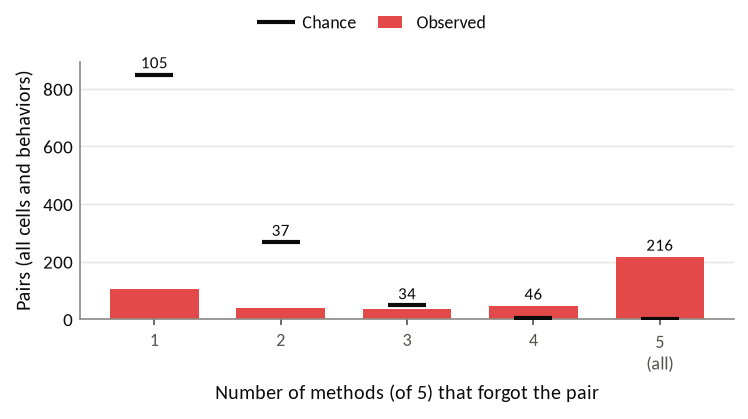

In [12]:
M = len(order_methods)
wide_status = P.pivot_table(index=SLOT + ['id'], columns='method', values='status', aggfunc='first').reindex(columns=order_methods)
wide_learned = P.pivot_table(index=SLOT + ['id'], columns='method', values='learned').reindex(columns=order_methods)
wide_final = P.pivot_table(index=SLOT + ['id'], columns='method', values='final').reindex(columns=order_methods)
known_all = (wide_learned > 0).all(axis=1)
core_base = wide_status[known_all]
forgot_by = (core_base == 'forgotten').sum(axis=1)
obs_k = np.bincount(forgot_by, minlength=M + 1)

rng = np.random.default_rng(CHANCE_SEED)
sim_k = np.zeros(M + 1)
n_sim = 500
for slot, g in core_base.groupby(level=[0, 1, 2]):
    draws = np.zeros((n_sim, len(g)), int)
    for m in order_methods:
        draws += draw_like(np.ones(len(g), bool), int((g[m] == 'forgotten').sum()), n_sim, rng)
    sim_k += np.array([np.bincount(row, minlength=M + 1) for row in draws]).mean(axis=0)

rows = []
for m in order_methods:
    f = core_base[m] == 'forgotten'
    rows.append({'Method': MLABEL[m], 'Forgotten (of pairs all methods knew), per cell×behavior': f.sum() / core_base.groupby(level=[0, 1, 2]).ngroups,
                 'Also forgotten by every other method (%)': 100 * (forgot_by[f] == M).mean() if f.any() else np.nan,
                 'Forgotten only by this method (%)': 100 * (forgot_by[f] == 1).mean() if f.any() else np.nan})
t5 = pd.DataFrame(rows)
show(t5, 'T5_core', f'Table 5. Core forgetting. {int(obs_k[M])} pairs are forgotten by all {M} methods '
     f'(chance {sim_k[M]:.1f}); {int(obs_k[1:].sum())} are forgotten by at least one.', decimals=1)

fig, ax = plt.subplots(figsize=(FULL_W * 0.75, 2.7))
x = np.arange(1, M + 1)
ax.bar(x, obs_k[1:], width=0.7, color=FORGET_C, zorder=2, label='Observed')
ax.plot(x, sim_k[1:], lw=0, marker='_', ms=18, mew=2, color=INK, zorder=3, label='Chance')
for xi, v, c in zip(x, obs_k[1:], sim_k[1:]):
    ax.annotate(str(int(v)), (xi, max(v, c)), xytext=(0, 3), textcoords='offset points', ha='center', fontsize=8)
ax.set_xticks(x, [str(i) if i < M else f'{i}\n(all)' for i in x])
ax.set_xlabel(f'Number of methods (of {M}) that forgot the pair')
ax.set_ylabel('Pairs (all cells and behaviors)')
clean_axis(ax, 'y')
fig.legend(loc='outside upper center', ncol=2)
show_fig(fig, 'F4_core_forgetting',
         'Among pairs that every method knew right after learning, how many methods forgot each one. A tall right '
         'bar means a shared core of pairs that no replay method protects. Black: expected by chance.')

## 8. Which pairs does replay save, and which does it newly forget?

Compared with No replay in the same cell (pairs both knew right after learning):

- **saved**: No replay forgot it, the method kept it;
- **newly forgotten**: No replay kept it, the method forgot it;
- **forgotten by both**.

Method,No replay forgot (per run),Saved,Forgotten by both,Newly forgotten,Saved − newly forgotten,Saved (% of No-replay forgotten)
Random 10%,50.12,13.25,36.88,3.50,9.75,26.43
Random 14.3%,49.00,13.50,35.50,3.75,9.75,27.55
MFR (ours),48.88,16.50,32.38,3.50,13.00,33.76
Lowest margin,49.25,17.50,31.75,4.25,13.25,35.53


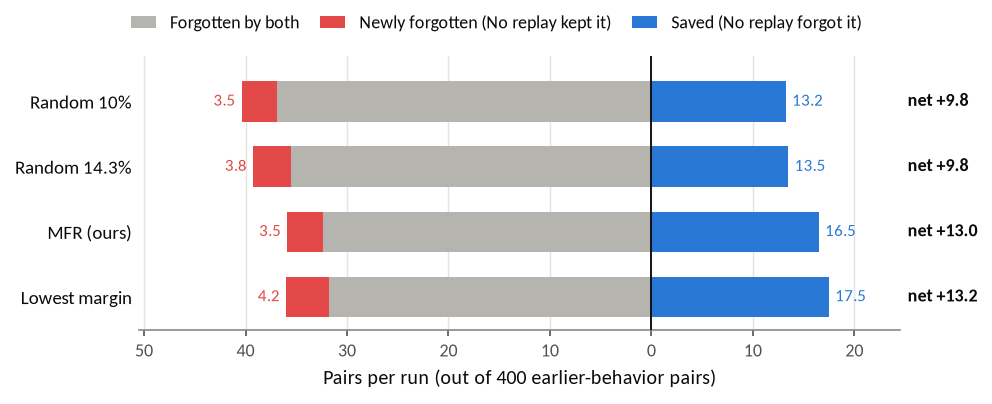

In [13]:
rows = []
for m in REPLAY:
    both_known = (wide_learned['none'] > 0) & (wide_learned[m] > 0)
    s_none, s_m = wide_status.loc[both_known, 'none'], wide_status.loc[both_known, m]
    n_slots = wide_status.loc[both_known].groupby(level=[0, 1]).ngroups   # runs (order, seed)
    saved = ((s_none == 'forgotten') & (s_m == 'kept')).sum() / n_slots
    new = ((s_none == 'kept') & (s_m == 'forgotten')).sum() / n_slots
    both = ((s_none == 'forgotten') & (s_m == 'forgotten')).sum() / n_slots
    none_f = (s_none == 'forgotten').sum() / n_slots
    rows.append({'Method': MLABEL[m], 'key': m, 'No replay forgot (per run)': none_f, 'Saved': saved,
                 'Forgotten by both': both, 'Newly forgotten': new, 'Saved − newly forgotten': saved - new,
                 'Saved (% of No-replay forgotten)': 100 * saved / none_f if none_f else np.nan})
t6 = pd.DataFrame(rows)
show(t6.drop(columns='key'), 'T6_saved_vs_no_replay', 'Table 6. Compared with No replay, per run (two earlier behaviors)', decimals=2)

fig, ax = plt.subplots(figsize=(FULL_W, 0.4 * len(REPLAY) + 1.0))
for y, r in t6.iterrows():
    ax.barh(y, -r['Forgotten by both'], height=0.62, color='#b5b4ae', zorder=2, label='Forgotten by both' if y == 0 else None)
    ax.barh(y, -r['Newly forgotten'], left=-r['Forgotten by both'], height=0.62, color=FORGET_C, zorder=2,
            label='Newly forgotten (No replay kept it)' if y == 0 else None)
    ax.barh(y, r['Saved'], height=0.62, color=RECOVER_C, zorder=2, label='Saved (No replay forgot it)' if y == 0 else None)
    ax.annotate(f"{r['Newly forgotten']:.1f}", (-(r['Forgotten by both'] + r['Newly forgotten']), y), xytext=(-3, 0),
                textcoords='offset points', ha='right', va='center', fontsize=8, color=FORGET_C)
    ax.annotate(f"{r['Saved']:.1f}", (r['Saved'], y), xytext=(3, 0), textcoords='offset points', va='center',
                fontsize=8, color=RECOVER_C)
    ax.text(1.01, y, f"net {num(r['Saved − newly forgotten'], 1, sign=True)}", transform=ax.get_yaxis_transform(),
            va='center', fontsize=8.5, fontweight='bold')
ax.axvline(0, color=INK, lw=0.9, zorder=3)
method_axis(ax, REPLAY)
lim = (t6['Forgotten by both'] + t6['Newly forgotten']).max()
ax.set_xlim(-lim * 1.25, max(t6['Saved'].max() * 1.4, 1))
ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f'{abs(v):g}'))
ax.set_xlabel('Pairs per run (out of 400 earlier-behavior pairs)')
clean_axis(ax, 'x')
fig.legend(loc='outside upper center', ncol=3)
show_fig(fig, 'F5_saved_vs_no_replay',
         'What replay changes compared with No replay in the same cell. Right (blue): pairs No replay forgot but the '
         'method kept. Left: pairs the method forgot, split into those No replay also forgot (grey) and those No replay '
         'kept (red). Net = saved − newly forgotten.')

### Who saves what: pairs No replay forgot, by which replay methods kept them

For pairs No replay forgot and every method knew, the combination of replay methods that kept the pair.
Black ticks: chance (each method keeps the same number of these pairs at random).

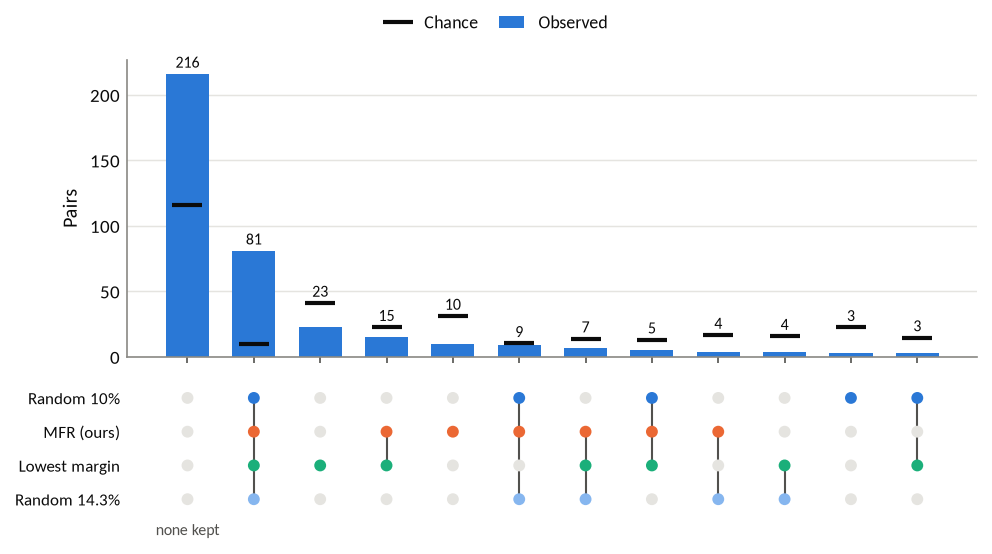

In [14]:
up = [m for m in UPSET_METHODS if m in REPLAY][:4]
if len(up) >= 2:
    base_idx = known_all & (wide_status['none'] == 'forgotten')
    sub = wide_status.loc[base_idx, up] == 'kept'
    combo = sub.apply(lambda r: tuple(m for m in up if r[m]), axis=1)
    obs_c = combo.value_counts()
    rng = np.random.default_rng(CHANCE_SEED)
    sim_c = Counter()
    n_sim = 500
    for slot, g in sub.groupby(level=[0, 1, 2]):
        draws = {m: draw_like(np.ones(len(g), bool), int(g[m].sum()), n_sim, rng) for m in up}
        for t in range(n_sim):
            for i in range(len(g)):
                sim_c[tuple(m for m in up if draws[m][t, i])] += 1 / n_sim
    combos = sorted(set(obs_c.index) | {c for c, v in sim_c.items() if v >= 0.5},
                    key=lambda c: (-obs_c.get(c, 0)))[:12]
    fig, (ax, ax2) = plt.subplots(2, 1, figsize=(FULL_W, 3.6), sharex=True, height_ratios=[2.2, 1])
    x = np.arange(len(combos))
    ax.bar(x, [obs_c.get(c, 0) for c in combos], width=0.65, color=RECOVER_C, zorder=2, label='Observed')
    ax.plot(x, [sim_c.get(c, 0) for c in combos], lw=0, marker='_', ms=14, mew=2, color=INK, zorder=3, label='Chance')
    for xi, c in zip(x, combos):
        ax.annotate(str(obs_c.get(c, 0)), (xi, max(obs_c.get(c, 0), sim_c.get(c, 0))), xytext=(0, 3), textcoords='offset points',
                    ha='center', fontsize=7.5)
    ax.set_ylabel('Pairs')
    clean_axis(ax, 'y')
    for yi, m in enumerate(up):
        ax2.scatter(x, np.full(len(x), yi), s=22, color=[MCOLOR[m] if m in c else '#e5e4e0' for c in combos], zorder=2)
    for xi, c in zip(x, combos):
        ys = [up.index(m) for m in c]
        if len(ys) > 1:
            ax2.plot([xi, xi], [min(ys), max(ys)], color=INK2, lw=1, zorder=1)
    ax2.set_yticks(range(len(up)), [MLABEL[m] for m in up], fontsize=8)
    ax2.set_ylim(len(up) - 0.5, -0.5)
    ax2.set_xticks(x, ['none kept' if not c else '' for c in combos], fontsize=7.5)
    no_frame(ax2)
    fig.legend(loc='outside upper center', ncol=2)
    show_fig(fig, 'F6_who_saves_what',
             'Pairs that No replay forgot (and every method knew), grouped by which replay methods kept them (dots). '
             'Left-most columns are the most common combinations. Black ticks: chance.')

## 9. What makes a pair fragile?

For pairs a method knew right after learning: how well does each feature separate forgotten from kept pairs?

**AUC** = probability that a random forgotten pair has a *higher* value of the feature than a random kept pair
(0.5 = no relation; below 0.5 = forgotten pairs have lower values). Then the forget rate per fifth (quintile) of each
feature.

Feature,All methods,No replay,Random 10%,Random 14.3%,MFR (ours),Lowest margin,Median (forgotten),Median (kept)
Margin right after learning,0.259,0.315,0.249,0.238,0.228,0.242,0.005,0.025
Prompt length (tokens),0.515,0.485,0.521,0.526,0.520,0.532,58.000,58.000
Chosen length (tokens),0.420,0.384,0.412,0.433,0.438,0.446,105.000,139.000
Rejected length (tokens),0.629,0.598,0.635,0.651,0.650,0.624,148.000,107.000
Chosen − rejected length,0.255,0.258,0.238,0.237,0.250,0.293,-50.000,23.000
Margin before learning,0.365,0.361,0.351,0.370,0.360,0.387,-0.000,0.000


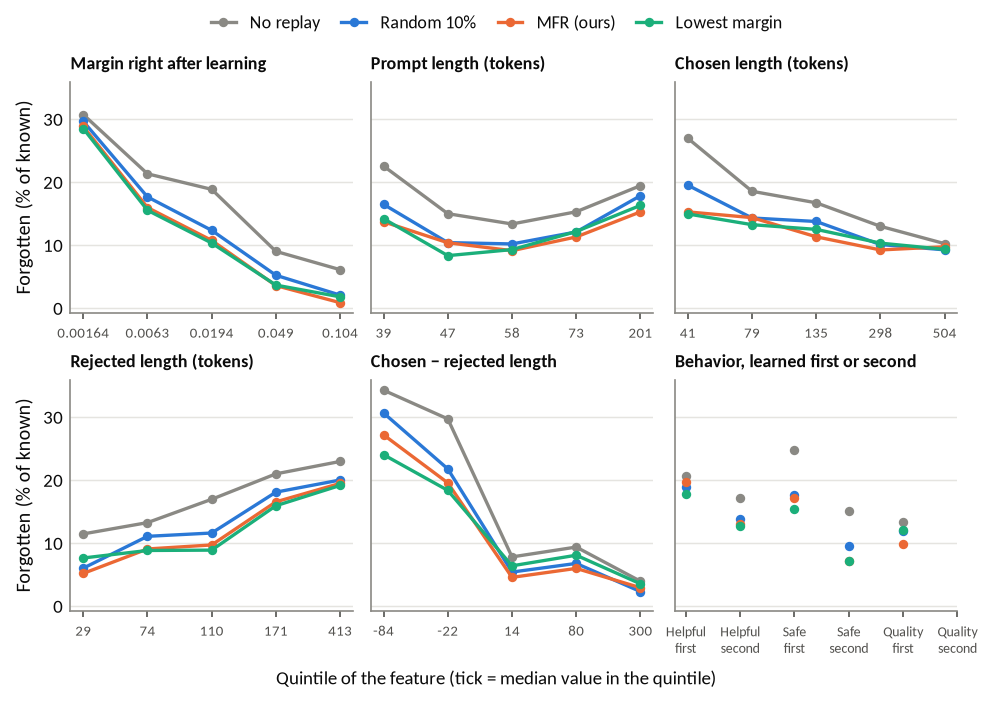

In [15]:
FEATURES = {'learned': 'Margin right after learning', 'prompt_tokens': 'Prompt length (tokens)',
            'chosen_tokens': 'Chosen length (tokens)', 'rejected_tokens': 'Rejected length (tokens)',
            'length_gap': 'Chosen − rejected length', 'before': 'Margin before learning'}
FEATURES = {k: v for k, v in FEATURES.items() if P[k].notna().mean() > 0.5}

def auc(values, labels):
    v, y = np.asarray(values, float), np.asarray(labels, bool)
    ok = np.isfinite(v)
    v, y = v[ok], y[ok]
    n1, n0 = y.sum(), (~y).sum()
    if n1 == 0 or n0 == 0:
        return np.nan
    r = pd.Series(v).rank().to_numpy()
    return (r[y].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

kp = P[P['learned'] > 0].assign(forgot=lambda t: t['status'] == 'forgotten')
rows = []
for feat, label in FEATURES.items():
    row = {'Feature': label, 'All methods': auc(kp[feat], kp['forgot'])}
    for m in order_methods:
        g = kp[kp['method'] == m]
        row[MLABEL[m]] = auc(g[feat], g['forgot'])
    row['Median (forgotten)'] = kp.loc[kp['forgot'], feat].median()
    row['Median (kept)'] = kp.loc[~kp['forgot'], feat].median()
    rows.append(row)
t7 = pd.DataFrame(rows)
show(t7, 'T7_what_predicts_forgetting', 'Table 7. AUC of each feature for "forgotten" (vs kept), pairs known right after learning', decimals=3)

cat_rows = []
for (m, d, pos_), g in kp.groupby(['method', 'dataset', 'position']):
    cat_rows.append({'method': m, 'dataset': d, 'position': pos_, 'rate': 100 * g['forgot'].mean()})
cats = pd.DataFrame(cat_rows)

key = [m for m in KEY_METHODS if m in order_methods]
feats = list(FEATURES)[:5]
fig, axes = plt.subplots(2, 3, figsize=(FULL_W, 4.6), sharey=True)
axes = axes.ravel()
for ax, feat in zip(axes, feats):
    q = pd.qcut(kp[feat].rank(method='first'), 5, labels=False)
    centers = kp.groupby(q)[feat].median()
    for m in key:
        g = kp[kp['method'] == m]
        r = g.groupby(q[g.index])['forgot'].mean() * 100
        ax.plot(range(5), r.reindex(range(5)), marker='o', ms=3.5, lw=1.6, color=MCOLOR[m], label=MLABEL[m])
    ax.set_xticks(range(5), [f'{c:.3g}' for c in centers], fontsize=7)
    ax.set_title(FEATURES[feat], fontsize=8.5)
    clean_axis(ax, 'y')
ax = axes[5]
labels_c = [f'{DLABEL[d]}\n{pos_}' for d in DATASETS for pos_ in ['first', 'second']]
for m in key:
    vals = [cats[(cats['method'] == m) & (cats['dataset'] == d) & (cats['position'] == pos_)]['rate'].mean()
            for d in DATASETS for pos_ in ['first', 'second']]
    ax.plot(range(6), vals, marker='o', ms=3.5, lw=0, color=MCOLOR[m])
ax.set_xticks(range(6), labels_c, fontsize=6.5)
ax.set_title('Behavior, learned first or second', fontsize=8.5)
clean_axis(ax, 'y')
for ax in axes[::3]:
    ax.set_ylabel('Forgotten (% of known)')
fig.supxlabel('Quintile of the feature (tick = median value in the quintile)', fontsize=9)
fig.legend(*axes[0].get_legend_handles_labels(), loc='outside upper center', ncol=len(key))
show_fig(fig, 'F7_what_predicts_forgetting',
         'Forget rate (pairs known right after learning that are wrong at the end) by quintile of each pair feature, per '
         'method. Last panel: by behavior and whether it was learned first or second.')

## 10. How margins move, stage by stage

Pairs of the **first** behavior (learned at stage 1, then two more stages). Mean margin after each stage, for each
group of pairs. Then one cell in detail: every pair's margin right after learning vs at the end.

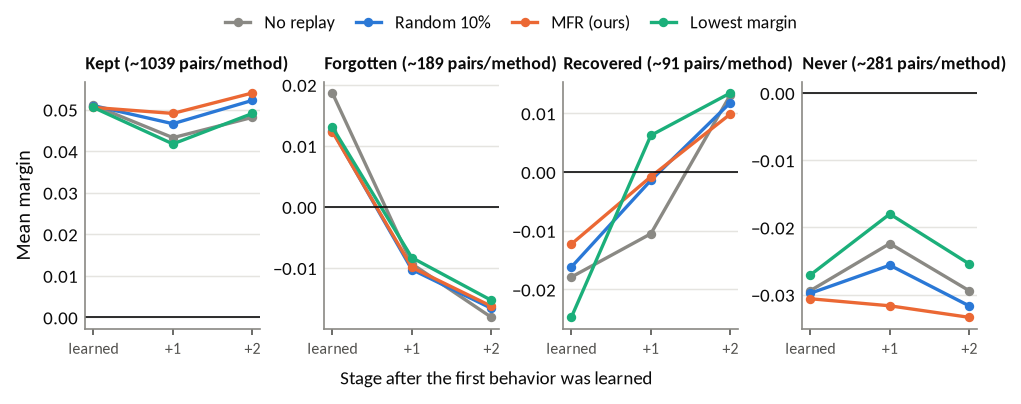

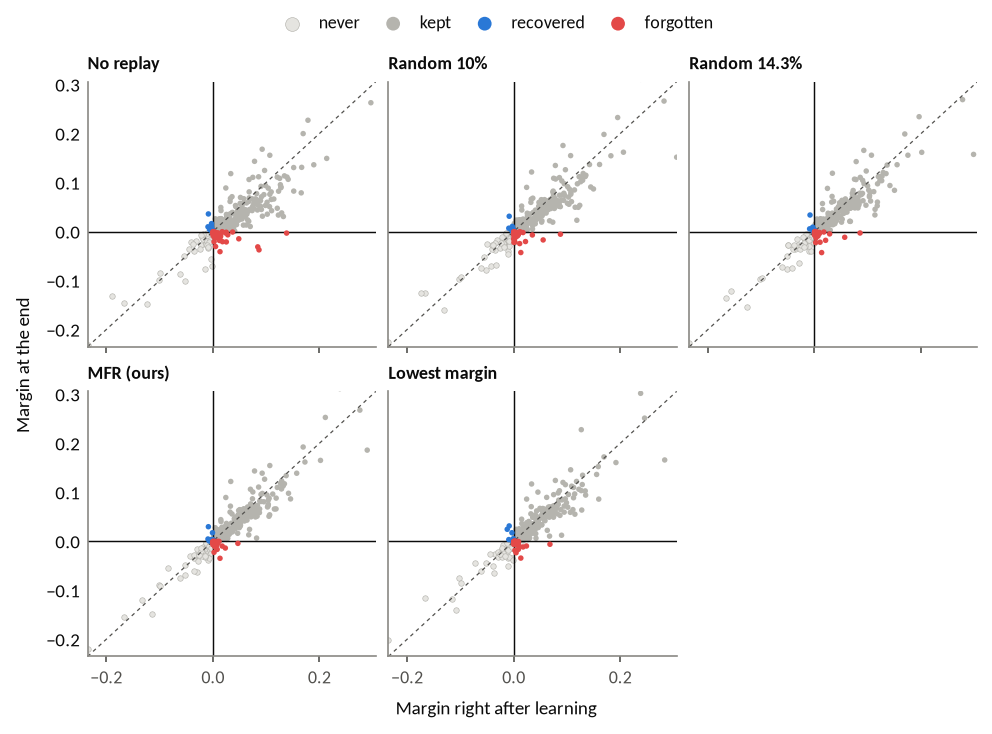

In [16]:
first = P[P['learned_at'] == 1]
traj = first.groupby(['method', 'status'])[['m1', 'm2', 'm3']].mean()
groups_ = ['kept', 'forgotten', 'recovered', 'never']
fig, axes = plt.subplots(1, 4, figsize=(FULL_W, 2.6), sharey=False)
for ax, st in zip(axes, groups_):
    for m in key:
        if (m, st) in traj.index:
            ax.plot([1, 2, 3], traj.loc[(m, st)].to_numpy(), marker='o', ms=3.5, lw=1.6, color=MCOLOR[m], label=MLABEL[m])
    ax.axhline(0, color=INK, lw=0.8)
    ax.set_xticks([1, 2, 3], ['learned', '+1', '+2'], fontsize=7.5)
    n_ = (first['status'] == st).sum() / max(first['method'].nunique(), 1)
    ax.set_title(f'{st.capitalize()} (~{n_:.0f} pairs/method)', fontsize=8.5)
    clean_axis(ax, 'y')
axes[0].set_ylabel('Mean margin')
fig.supxlabel('Stage after the first behavior was learned', fontsize=9)
fig.legend(*axes[0].get_legend_handles_labels(), loc='outside upper center', ncol=len(key))
show_fig(fig, 'F8_margin_trajectories',
         'Mean margin of first-behavior pairs after each stage, split by what happened to them by the end (kept, '
         'forgotten, recovered, never learned). Pooled over orders and seeds.')

eo, es = EXAMPLE_CELL
cell = P[(P['order_id'] == eo) & (P['seed'] == es)]
SCOL = {'kept': '#b5b4ae', 'forgotten': FORGET_C, 'recovered': RECOVER_C, 'never': '#e5e4e0'}
ncol = min(3, len(order_methods)); nrow = math.ceil(len(order_methods) / ncol)
fig, axes = plt.subplots(nrow, ncol, figsize=(FULL_W, 2.1 * nrow + 0.6), sharex=True, sharey=True, squeeze=False)
lo = np.nanquantile(cell[['learned', 'final']].to_numpy(), 0.005)
hi = np.nanquantile(cell[['learned', 'final']].to_numpy(), 0.995)
for ax, m in zip(axes.ravel(), order_methods):
    g = cell[cell['method'] == m]
    for st in ['never', 'kept', 'recovered', 'forgotten']:
        h_ = g[g['status'] == st]
        ax.scatter(h_['learned'], h_['final'], s=7, color=SCOL[st], edgecolor='none' if st != 'never' else '#b5b4ae',
                   linewidth=0.3, zorder=3 if st in ('forgotten', 'recovered') else 2,
                   label=f'{st}' if m == order_methods[0] else None)
    ax.axhline(0, color=INK, lw=0.7); ax.axvline(0, color=INK, lw=0.7)
    ax.plot([lo, hi], [lo, hi], color=INK2, lw=0.6, ls=(0, (3, 3)))
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
    ax.set_title(MLABEL[m], fontsize=8.5)
for ax in axes.ravel()[len(order_methods):]:
    ax.axis('off')
fig.supxlabel('Margin right after learning', fontsize=9)
fig.supylabel('Margin at the end', fontsize=9)
fig.legend(loc='outside upper center', ncol=4, markerscale=2.5)
show_fig(fig, 'F9_margin_scatter_one_cell',
         f'Every earlier-behavior pair in order {eo} ({ORDER_NAME.get(eo, "")}), seed {es}: margin right after learning '
         f'vs at the end. Red: forgotten (crossed from right to wrong); blue: recovered. Dashed: no change.')

## 11. Mechanism: were pairs protected when similar training pairs were replayed?

Replay uses **training** pairs; we evaluate **validation** pairs. To link them, each validation pair is matched to
its most similar training pairs of the same behavior by word overlap (TF-IDF cosine on prompt + chosen response).
For each run we then ask: was at least one of a validation pair's `NEIGHBORS` nearest training pairs replayed after
the behavior was learned? And how similar is the most similar replayed training pair?

Word overlap is a rough notion of similarity; treat this as suggestive.

similarity matrices: {'helpful': (200, 2000), 'safe': (200, 2000), 'quality': (200, 2000)}


Method,Pairs with a replayed neighbor (%),Forget rate: neighbor replayed (%),Forget rate: no neighbor replayed (%),AUC of best replayed similarity for forgotten
Random 10%,35.697,12.629,13.703,0.430
Random 14.3%,44.540,12.627,13.472,0.437
MFR (ours),23.200,11.348,12.105,0.420
Lowest margin,18.424,16.036,11.117,0.482


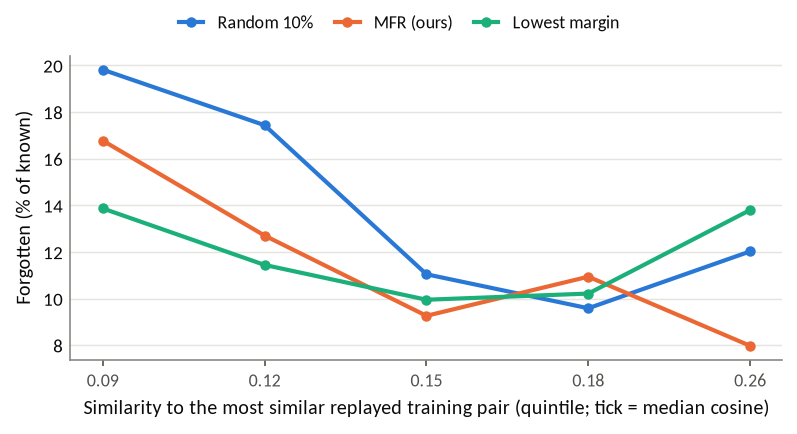

In [17]:
from scipy import sparse
TOKEN = re.compile(r"[a-z0-9']+")

def tfidf_rows(token_lists, vocab, idf):
    data, indices, indptr = [], [], [0]
    for toks in token_lists:
        c = Counter(t for t in toks if t in vocab)
        for w, n in c.items():
            indices.append(vocab[w]); data.append((1 + math.log(n)) * idf[vocab[w]])
        indptr.append(len(indices))
    X = sparse.csr_matrix((data, indices, indptr), shape=(len(token_lists), len(vocab)))
    norms = np.sqrt(np.asarray(X.multiply(X).sum(axis=1))).ravel()
    return sparse.diags(1 / np.maximum(norms, 1e-12)) @ X

SIM, TRAIN_IDS = {}, {}
for d in DATASETS:
    train_path = DATA_DIR / f'{d}_train.jsonl'
    if not train_path.exists():
        print('No training file for', d, '- skipping the replay link')
        continue
    train = read_jsonl(train_path)
    val = [TEXT[i] for i in sorted(pair_info.loc[pair_info['dataset'] == d, 'id'])]
    tok_t = [TOKEN.findall((r['prompt'] + ' ' + r['chosen']).lower()) for r in train]
    tok_v = [TOKEN.findall((r['prompt'] + ' ' + r['chosen']).lower()) for r in val]
    df_ = Counter()
    for toks in tok_t + tok_v:
        df_.update(set(toks))
    words = [w for w, c in df_.most_common(40000) if c >= 2]
    vocab = {w: i for i, w in enumerate(words)}
    n_docs = len(tok_t) + len(tok_v)
    idf = np.array([math.log((1 + n_docs) / (1 + df_[w])) + 1 for w in words])
    S = (tfidf_rows(tok_v, vocab, idf) @ tfidf_rows(tok_t, vocab, idf).T).toarray()
    SIM[d] = pd.DataFrame(S, index=[r['id'] for r in val], columns=[r['id'] for r in train])
print('similarity matrices:', {d: s.shape for d, s in SIM.items()})

link_rows = []
for (method, order_id, seed), rec in records.items():
    if method == 'none':
        continue
    order, last = rec['order'], len(rec['order'])
    logs = {}
    for st in range(2, last + 1):
        path = stage_dir(rec, st) / 'replay_log.csv'
        if path.exists():
            logs[st] = pd.read_csv(path)
    for k, d in enumerate(order[:-1], 1):
        if d not in SIM:
            continue
        replayed = set()
        for st, lg in logs.items():
            if st > k and len(lg):
                replayed |= set(lg.loc[lg['dataset'] == d, 'id']) if 'dataset' in lg else set(lg['id'])
        S = SIM[d]
        cols = [c for c in S.columns if c in replayed]
        nn = np.argsort(-S.to_numpy(), axis=1)[:, :NEIGHBORS]
        is_rep = np.isin(S.columns.to_numpy(), list(replayed))
        nn_hit = is_rep[nn].any(axis=1)
        best = S[cols].max(axis=1) if cols else pd.Series(np.nan, index=S.index)
        link_rows.append(pd.DataFrame({'id': S.index, 'method': method, 'order_id': order_id, 'seed': seed,
                                       'dataset': d, 'neighbor_replayed': nn_hit, 'best_replayed_sim': best.to_numpy(),
                                       'replayed_pairs': len(replayed)}))
if link_rows:
    LINK = pd.concat(link_rows, ignore_index=True).merge(P[['id', 'method', 'order_id', 'seed', 'dataset', 'status', 'learned']],
                                                       on=['id', 'method', 'order_id', 'seed', 'dataset'])
    LK = LINK[LINK['learned'] > 0].assign(forgot=lambda t: t['status'] == 'forgotten')
    rows = []
    for m in REPLAY:
        g = LK[LK['method'] == m]
        if g.empty:
            continue
        rows.append({'Method': MLABEL[m],
                     'Pairs with a replayed neighbor (%)': 100 * g['neighbor_replayed'].mean(),
                     'Forget rate: neighbor replayed (%)': 100 * g.loc[g['neighbor_replayed'], 'forgot'].mean(),
                     'Forget rate: no neighbor replayed (%)': 100 * g.loc[~g['neighbor_replayed'], 'forgot'].mean(),
                     'AUC of best replayed similarity for forgotten': auc(g['best_replayed_sim'], g['forgot'])})
    t8 = pd.DataFrame(rows)
    show(t8, 'T8_replay_link', f'Table 8. Forget rate of known validation pairs by whether one of their {NEIGHBORS} '
         'nearest training pairs was replayed (AUC < 0.5: forgotten pairs were less similar to what was replayed)', decimals=3)

    fig, ax = plt.subplots(figsize=(FULL_W * 0.8, 2.8))
    q = pd.qcut(LK['best_replayed_sim'].rank(method='first'), 5, labels=False)
    centers = LK.groupby(q)['best_replayed_sim'].median()
    for m in [m for m in key if m in REPLAY]:
        g = LK[LK['method'] == m]
        r = g.groupby(q[g.index])['forgot'].mean() * 100
        ax.plot(range(5), r.reindex(range(5)), marker='o', ms=4, color=MCOLOR[m], label=MLABEL[m])
    ax.set_xticks(range(5), [f'{c:.2f}' for c in centers])
    ax.set_xlabel('Similarity to the most similar replayed training pair (quintile; tick = median cosine)')
    ax.set_ylabel('Forgotten (% of known)')
    clean_axis(ax, 'y')
    fig.legend(loc='outside upper center', ncol=len(key))
    show_fig(fig, 'F10_replay_similarity',
             'Are validation pairs that resemble replayed training pairs forgotten less? Forget rate by how similar the '
             'pair is (word overlap) to the most similar training pair replayed after its behavior was learned.')

## 12. Look at the pairs

Each card shows one validation pair in one cell (order, seed): the prompt, the **chosen** (preferred) and
**rejected** responses, and every method's margin right after learning → at the end. Click "show all" to expand a
long text.

Groups (only groups whose methods you kept in the settings appear):

| group | meaning |
|---|---|
| `core` | forgotten by every method, including all replay methods |
| `saved_only_<method>` | No replay forgot it; only this replay method kept it |
| `saved_by_all` | No replay forgot it; every replay method kept it |
| `hurt_by_replay` | No replay kept it; every replay method forgot it |
| `recovered_by_all` | wrong after learning, right at the end for every method |
| `most_fragile` | forgotten in the largest share of runs overall (all orders, seeds, methods) |

Use `examples('core', n=10)`, `examples('saved_only_lowest_margin', dataset='safe')`, or `show_pair('safe-val-0012')`.

In [18]:
STATUS_STYLE = {'kept': ('#eeeeec', INK), 'forgotten': (FORGET_C, 'white'), 'recovered': (RECOVER_C, 'white'),
                'never': ('#f7f6f3', INK2)}

def _text_block(label, text, color):
    text = str(text or '')
    short = html.escape(text[:TEXT_CHARS])
    body = (f'{short}' if len(text) <= TEXT_CHARS else
            f'{short}… <details style="display:inline"><summary style="cursor:pointer;color:#2a78d6">show all '
            f'({len(text)} chars)</summary>{html.escape(text)}</details>')
    return (f'<div style="margin:6px 0"><div style="font-weight:600;color:{color};font-size:12px">{label}</div>'
            f'<div style="white-space:pre-wrap;font-size:12.5px;line-height:1.35;border-left:3px solid {color};'
            f'padding:3px 8px;background:#fafaf8">{body}</div></div>')

def pair_card(order_id, seed, dataset, pid, note=''):
    r = TEXT.get(pid, {})
    g = P[(P['order_id'] == order_id) & (P['seed'] == seed) & (P['id'] == pid)].set_index('method')
    k = int(g['learned_at'].iloc[0]) if len(g) else 0
    rows = ''
    for m in order_methods:
        if m not in g.index:
            continue
        x = g.loc[m]
        bg, fg = STATUS_STYLE[x['status']]
        flag = ' · borderline' if x['borderline'] and x['status'] in ('forgotten', 'recovered') else ''
        rows += (f'<tr><td style="padding:2px 8px">{MLABEL[m]}</td>'
                 f'<td style="padding:2px 8px;text-align:right">{x["learned"]:+.4f}</td>'
                 f'<td style="padding:2px 8px;text-align:right">{x["final"]:+.4f}</td>'
                 f'<td style="padding:2px 8px"><span style="background:{bg};color:{fg};padding:1px 7px;'
                 f'border-radius:9px;font-size:11.5px">{x["status"]}{flag}</span></td></tr>')
    toks = pair_info.set_index('id').loc[pid] if pid in set(pair_info['id']) else None
    meta = (f'prompt {toks["prompt_tokens"]:.0f} · chosen {toks["chosen_tokens"]:.0f} · rejected '
            f'{toks["rejected_tokens"]:.0f} tokens' if toks is not None else '')
    return (f'<div style="border:1px solid #ddd;border-radius:8px;padding:10px 14px;margin:10px 0;max-width:980px;'
            f'background:#ffffff;color:#0b0b0b">'
            f'<div style="font-size:13px"><b>{pid}</b> · {DLABEL.get(dataset, dataset)} · order {order_id} '
            f'({ORDER_NAME.get(order_id, "")}), seed {seed} · learned at stage {k} · source {r.get("source_dataset", "")}'
            f' · {meta}</div>'
            + (f'<div style="color:#52514e;font-size:12px;margin-top:2px">{html.escape(note)}</div>' if note else '')
            + f'<table style="border-collapse:collapse;font-size:12px;margin:6px 0"><tr style="color:#52514e">'
            f'<th style="padding:2px 8px;text-align:left">Method</th><th style="padding:2px 8px">after learning</th>'
            f'<th style="padding:2px 8px">at the end</th><th style="padding:2px 8px;text-align:left">status</th></tr>'
            f'{rows}</table>'
            + _text_block('Prompt', r.get('prompt'), INK2)
            + _text_block('Chosen (preferred)', r.get('chosen'), '#1baf7a')
            + _text_block('Rejected', r.get('rejected'), FORGET_C)
            + '</div>')

S_ = wide_status
L_ = wide_learned
known_all_ = (L_ > 0).all(axis=1)
unknown_all_ = (L_ <= 0).all(axis=1)
none_forgot = known_all_ & (S_['none'] == 'forgotten')
GROUPS = {'core': (known_all_ & (S_ == 'forgotten').all(axis=1), 'forgotten by every method')}
if REPLAY:
    for m in REPLAY:
        others = [x for x in REPLAY if x != m]
        mask = none_forgot & (S_[m] == 'kept') & ((S_[others] == 'forgotten').all(axis=1) if others else True)
        GROUPS[f'saved_only_{m}'] = (mask, f'No replay forgot it; only {MLABEL[m]} kept it')
    GROUPS['saved_by_all'] = (none_forgot & (S_[REPLAY] == 'kept').all(axis=1), 'No replay forgot it; every replay method kept it')
    GROUPS['hurt_by_replay'] = (known_all_ & (S_['none'] == 'kept') & (S_[REPLAY] == 'forgotten').all(axis=1),
                                'No replay kept it; every replay method forgot it')
GROUPS['recovered_by_all'] = (unknown_all_ & (S_ == 'recovered').all(axis=1), 'recovered by every method')
fragile_ids = per_pair[per_pair['runs'] >= 4].sort_values(['rate', 'runs'], ascending=False)

def group_members(name, dataset=None):
    if name == 'most_fragile':
        idx = []
        for (d, pid), r in fragile_ids.iterrows():
            if dataset and d != dataset:
                continue
            rows_ = P[(P['id'] == pid) & (P['status'] == 'forgotten')]
            if len(rows_):
                o, s = rows_.iloc[0][['order_id', 'seed']]
                idx.append(((int(o), int(s), d, pid), f'forgotten in {r["forgotten"]:.0f} of {r["runs"]:.0f} runs where it was known'))
        return idx
    mask, label = GROUPS[name]
    hits = S_[mask].index
    if dataset:
        hits = [h for h in hits if h[2] == dataset]
    drop = (wide_learned - wide_final).loc[list(hits)].mean(axis=1).sort_values(ascending=False)
    seen, out = set(), []
    for h in drop.index:
        if h[3] in seen:
            continue
        seen.add(h[3])
        out.append((h, label))
    return out

def examples(name, n=None, dataset=None):
    """Show example pairs of a group, largest margin drop first. Groups: list(GROUPS) + ['most_fragile']."""
    n = N_EXAMPLES if n is None else n
    members = group_members(name, dataset)
    display(HTML(f'<h4 style="margin:14px 0 2px">{name}: {len(members)} pairs'
                 f'{" (" + DLABEL[dataset] + ")" if dataset else ""}, showing {min(n, len(members))}</h4>'))
    html_ = ''.join(pair_card(o, s, d, pid, note) for (o, s, d, pid), note in members[:n])
    display(HTML(html_ or '<i>none</i>'))

def show_pair(pid):
    """One pair in every run where it was an earlier behavior: status grid + text."""
    g = P[P['id'] == pid]
    if g.empty:
        print(pid, 'is never an earlier behavior in the loaded runs (or the id is wrong).')
        return
    grid = g.pivot_table(index='method', columns=['order_id', 'seed'], values='status', aggfunc='first').reindex(order_methods)
    grid.index = [MLABEL[m] for m in grid.index]
    grid.columns = [f'O{o} S{s}' for o, s in grid.columns]
    colors = {k: f'background-color:{v[0]};color:{v[1]}' for k, v in STATUS_STYLE.items()}
    display(HTML(f'<h4 style="margin:14px 0 4px">{pid}: status in every run</h4>'))
    display(grid.style.map(lambda v: colors.get(v, '')))
    o, s, d = g.iloc[0][['order_id', 'seed', 'dataset']]
    display(HTML(pair_card(int(o), int(s), d, pid)))

counts = pd.DataFrame([{'Group': k, 'Meaning': v[1], 'Pairs (cell × pair)': int(v[0].sum()),
                        'Distinct pairs': len({h[3] for h in S_[v[0]].index})} for k, v in GROUPS.items()])
show(counts, 'T9_example_groups', 'Table 9. Size of each example group (pairs every method knew, or did not know)', decimals=0)

Group,Meaning,Pairs (cell × pair),Distinct pairs
core,forgotten by every method,216,100
saved_only_random,No replay forgot it; only Random 10% kept it,3,3
saved_only_random_high,No replay forgot it; only Random 14.3% kept it,1,1
saved_only_mfr,No replay forgot it; only MFR (ours) kept it,10,10
saved_only_lowest_margin,No replay forgot it; only Lowest margin kept it,23,17
saved_by_all,No replay forgot it; every replay method kept it,81,48
hurt_by_replay,No replay kept it; every replay method forgot it,9,9
recovered_by_all,recovered by every method,93,55


In [19]:
examples('core')

Method,after learning,at the end,status
No replay,+0.0669,-0.4406,forgotten
Random 10%,+0.0669,-0.4228,forgotten
Random 14.3%,+0.0669,-0.4787,forgotten
MFR (ours),+0.0669,-0.4559,forgotten
Lowest margin,+0.0669,-0.4543,forgotten
Method,after learning,at the end,status
No replay,+0.1032,-0.0858,forgotten
Random 10%,+0.1032,-0.0703,forgotten
Random 14.3%,+0.1032,-0.0615,forgotten
MFR (ours),+0.1032,-0.0594,forgotten


In [20]:
for m in REPLAY:
    examples(f'saved_only_{m}')

Method,after learning,at the end,status
No replay,+0.0194,-0.0041,forgotten
Random 10%,+0.0194,+0.0029,kept
Random 14.3%,+0.0194,-0.0053,forgotten
MFR (ours),+0.0194,-0.0033,forgotten
Lowest margin,+0.0194,-0.0141,forgotten
Method,after learning,at the end,status
No replay,+0.0056,-0.0001,forgotten · borderline
Random 10%,+0.0056,+0.0006,kept
Random 14.3%,+0.0056,-0.0012,forgotten · borderline
MFR (ours),+0.0056,-0.0008,forgotten · borderline


Method,after learning,at the end,status
No replay,+0.0383,-0.0067,forgotten
Random 10%,+0.0383,-0.0016,forgotten
Random 14.3%,+0.0383,+0.0005,kept
MFR (ours),+0.0383,-0.0016,forgotten
Lowest margin,+0.0383,-0.0007,forgotten · borderline


Method,after learning,at the end,status
No replay,+0.1264,-0.0499,forgotten
Random 10%,+0.0841,-0.0153,forgotten
Random 14.3%,+0.0876,-0.0074,forgotten
MFR (ours),+0.0811,+0.0070,kept
Lowest margin,+0.0881,-0.0188,forgotten
Method,after learning,at the end,status
No replay,+0.0835,-0.0570,forgotten
Random 10%,+0.0667,-0.0263,forgotten
Random 14.3%,+0.0685,-0.0173,forgotten
MFR (ours),+0.0686,+0.0021,kept


Method,after learning,at the end,status
No replay,+0.1234,-0.0570,forgotten
Random 10%,+0.1234,-0.0214,forgotten
Random 14.3%,+0.1234,-0.0166,forgotten
MFR (ours),+0.1234,-0.0041,forgotten
Lowest margin,+0.1234,+0.0047,kept
Method,after learning,at the end,status
No replay,+0.1098,-0.0082,forgotten
Random 10%,+0.0827,-0.0015,forgotten
Random 14.3%,+0.0729,-0.0081,forgotten
MFR (ours),+0.0575,-0.0133,forgotten


In [21]:
examples('saved_by_all')
examples('hurt_by_replay')

Method,after learning,at the end,status
No replay,+0.1704,-0.0033,forgotten
Random 10%,+0.1704,+0.0217,kept
Random 14.3%,+0.1704,+0.0329,kept
MFR (ours),+0.1704,+0.0462,kept
Lowest margin,+0.1704,+0.0347,kept
Method,after learning,at the end,status
No replay,+0.1360,-0.0748,forgotten
Random 10%,+0.1360,+0.0090,kept
Random 14.3%,+0.1360,+0.0097,kept
MFR (ours),+0.1360,+0.0395,kept


Method,after learning,at the end,status
No replay,+0.0410,+0.0141,kept
Random 10%,+0.0410,-0.0137,forgotten
Random 14.3%,+0.0410,-0.0051,forgotten
MFR (ours),+0.0410,-0.0025,forgotten
Lowest margin,+0.0410,-0.0309,forgotten
Method,after learning,at the end,status
No replay,+0.0389,+0.0013,kept
Random 10%,+0.0313,-0.0011,forgotten · borderline
Random 14.3%,+0.0275,-0.0018,forgotten
MFR (ours),+0.0238,-0.0008,forgotten · borderline


In [22]:
examples('recovered_by_all')
examples('most_fragile')

Method,after learning,at the end,status
No replay,-0.0002,+0.0003,recovered · borderline
Random 10%,-0.0002,+0.0006,recovered · borderline
Random 14.3%,-0.0002,+0.0008,recovered · borderline
MFR (ours),-0.0002,+0.0006,recovered · borderline
Lowest margin,-0.0002,+0.0006,recovered · borderline
Method,after learning,at the end,status
No replay,-0.0001,+0.0019,recovered · borderline
Random 10%,-0.0001,+0.0009,recovered · borderline
Random 14.3%,-0.0001,+0.0004,recovered · borderline
MFR (ours),-0.0001,+0.0007,recovered · borderline


Method,after learning,at the end,status
No replay,+0.0098,-0.0057,forgotten
Random 10%,+0.0064,-0.0050,forgotten
Random 14.3%,+0.0067,-0.0049,forgotten
MFR (ours),+0.0013,-0.0044,forgotten
Lowest margin,+0.0027,-0.0034,forgotten
Method,after learning,at the end,status
No replay,+0.0181,-0.0207,forgotten
Random 10%,+0.0113,-0.0246,forgotten
Random 14.3%,+0.0105,-0.0218,forgotten
MFR (ours),+0.0081,-0.0166,forgotten


In [23]:
# Look at any pair yourself, for example the most fragile one:
if len(fragile_ids):
    show_pair(fragile_ids.index[0][1])

,O1 S0,O1 S1,O2 S0,O2 S1,O4 S0,O4 S1
No replay,forgotten,forgotten,forgotten,forgotten,forgotten,forgotten
Random 10%,forgotten,forgotten,forgotten,forgotten,forgotten,forgotten
Random 14.3%,forgotten,forgotten,forgotten,forgotten,forgotten,forgotten
MFR (ours),forgotten,forgotten,forgotten,forgotten,forgotten,forgotten
Lowest margin,forgotten,forgotten,forgotten,forgotten,forgotten,forgotten


Method,after learning,at the end,status
No replay,+0.0098,-0.0057,forgotten
Random 10%,+0.0064,-0.0050,forgotten
Random 14.3%,+0.0067,-0.0049,forgotten
MFR (ours),+0.0013,-0.0044,forgotten
Lowest margin,+0.0027,-0.0034,forgotten


## 13. Key findings (auto-generated) and the full pair table

`save('key_findings')` writes this text; `save('D1')` writes the full pair-level table (no text, ids only) as CSV.

In [24]:
lines = []
fo = ov_forgot.assign(r=lambda t: t['ratio'])
if len(fo):
    lines.append(f'Forgotten-pair overlap between methods: Jaccard {fo["observed"].min():.2f}–{fo["observed"].max():.2f} '
                 f'(chance {fo["chance"].min():.2f}–{fo["chance"].max():.2f}; {fo["ratio"].min():.1f}–{fo["ratio"].max():.1f}× chance).')
if len(t3):
    lines.append(f'Same method, other seed: Jaccard {t3["Same method, other seed"].mean():.2f} on average '
                 f'(chance {t3["chance (seed)"].mean():.2f}); other methods, same seed: '
                 f'{t3["Other methods, same seed (mean)"].mean():.2f} (chance {t3["chance (method)"].mean():.2f}).')
if len(t4):
    lines.append(f'Per-pair forget rates across orders: Spearman ρ {t4["Spearman ρ"].min():.2f}–{t4["Spearman ρ"].max():.2f}.')
lines.append(f'The 10% most-forgotten pairs account for {TOP10[0]:.0f}% of all forgetting events (chance {TOP10[1]:.0f}%).')
lines.append(f'{int(obs_k[M])} pairs were forgotten by all {M} methods in the same cell (chance {sim_k[M]:.1f}).')
for _, r in t6.iterrows():
    lines.append(f'{r["Method"]}: saves {r["Saved"]:.1f} pairs per run that No replay forgot '
                 f'({r["Saved (% of No-replay forgotten)"]:.0f}%), newly forgets {r["Newly forgotten"]:.1f}.')
if len(t7):
    best = t7.iloc[(t7['All methods'] - 0.5).abs().argmax()]
    lines.append(f'Strongest single predictor of forgetting: {best["Feature"]} (AUC {best["All methods"]:.2f}).')
if link_rows and len(t8):
    for _, r in t8.iterrows():
        lines.append(f'{r["Method"]}: forget rate {r["Forget rate: neighbor replayed (%)"]:.1f}% with a replayed neighbor '
                     f'vs {r["Forget rate: no neighbor replayed (%)"]:.1f}% without.')
TEXTS['key_findings'] = '\n'.join(lines)
print(TEXTS['key_findings'])

D1 = P.drop(columns=[c for c in ['prompt_tokens', 'chosen_tokens', 'rejected_tokens'] if c in P])
TABLES['D1_pair_table'] = D1
print(f'\nD1_pair_table: {len(D1):,} rows, columns: {", ".join(D1.columns)}')

Forgotten-pair overlap between methods: Jaccard 0.55–0.83 (chance 0.07–0.08; 7.4–11.5× chance).
Same method, other seed: Jaccard 0.46 on average (chance 0.07); other methods, same seed: 0.68 (chance 0.07).
Per-pair forget rates across orders: Spearman ρ 0.42–0.88.
The 10% most-forgotten pairs account for 60% of all forgetting events (chance 22%).
216 pairs were forgotten by all 5 methods in the same cell (chance 0.2).
Random 10%: saves 13.2 pairs per run that No replay forgot (26%), newly forgets 3.5.
Random 14.3%: saves 13.5 pairs per run that No replay forgot (28%), newly forgets 3.8.
MFR (ours): saves 16.5 pairs per run that No replay forgot (34%), newly forgets 3.5.
Lowest margin: saves 17.5 pairs per run that No replay forgot (36%), newly forgets 4.2.
Strongest single predictor of forgetting: Chosen − rejected length (AUC 0.26).
Random 10%: forget rate 12.6% with a replayed neighbor vs 13.7% without.
Random 14.3%: forget rate 12.6% with a replayed neighbor vs 13.5% without.
MFR (o

## 14. Save what you want

| Output | What |
|---|---|
| `F1`, Table 2a–c | overlap between methods vs chance |
| `F2`, Table 3 | same method across seeds vs other methods |
| Table 4, `F3` | same pairs across orders; how concentrated forgetting is |
| `F4`, Table 5 | the core every method forgets |
| `F5`, `F6`, Table 6 | saved / newly forgotten vs No replay; who saves what |
| `F7`, Table 7 | what predicts forgetting |
| `F8`, `F9` | margin trajectories; one cell in detail |
| `F10`, Table 8 | link to replayed training pairs |
| Table 9 + cards | example pairs |
| `key_findings`, `D1` | text summary; full pair table |

In [25]:
list_outputs()

# save('F1', 'F3', 'F4', 'F5')
# save('T2', 'T5', 'T6')
# save('key_findings', 'D1')
# save('all')
# zip_saved()

Figures:
   save('F1')             ->  F1_overlap_between_methods
   save('F2')             ->  F2_seed_vs_method_overlap
   save('F3')             ->  F3_how_concentrated
   save('F4')             ->  F4_core_forgetting
   save('F5')             ->  F5_saved_vs_no_replay
   save('F6')             ->  F6_who_saves_what
   save('F7')             ->  F7_what_predicts_forgetting
   save('F8')             ->  F8_margin_trajectories
   save('F9')             ->  F9_margin_scatter_one_cell
   save('F10')            ->  F10_replay_similarity
Tables:
   save('T00_inventory')  ->  T00_inventory
   save('T00_stage1_check')->  T00_stage1_check
   save('T01')            ->  T01_text_lengths
   save('T1')             ->  T1_pair_counts
   save('T2a')            ->  T2a_overlap_forgotten
   save('T2b')            ->  T2b_overlap_recovered
   save('T2c')            ->  T2c_overlap_robustness
   save('T3')             ->  T3_seed_vs_method_overlap
   save('T4')             ->  T4_fragility_across_orde